# Validated GenAI Analysis of Public Comments on the FTC's Personalized-Pricing Policy

## 1. Business understanding

**Context.** In August 2026 the Federal Trade Commission (FTC) proposed an enforcement policy on *personalized pricing*: businesses using a consumer's personal data to estimate what that person will pay, and setting their price accordingly. The proposal does not ban the practice. It says businesses may break the law if they fail to clearly disclose that a price is personalized, why, and what data was used. The public comment period (docket FTC-2026-1057) closed on September 25, 2026, with 3,706 public comments.

**The business problem.** Regulators, law firms and public-affairs teams must read and summarize thousands of comments like these by hand. GenAI could do this faster and more cheaply, but a misread comment misrepresents the public record. Before anyone relies on it, the AI's accuracy has to be measured against careful human judgment.

**Research questions.**

*Workflow (for organizations adopting GenAI):*
1. How accurately does an LLM classify comments compared with human coders?
2. What does it cost per comment compared with human analysts?
3. Where does it fail?
4. What controls make it safe to use?

*Findings (for companies that use personalized pricing):*

5. What do individual commenters object to: the price difference, the use of their data, or the lack of disclosure?
6. What do they want the FTC to do?

**Scope.** This study analyzes comments from **individuals**. Submissions from organizations (companies, trade groups, advocacy groups) are mostly long attached documents that need a different method; comparing them with individuals is left for future work.

**Approach.** Understand → Use → Evaluate → Govern. Findings are reported only for labels the AI has been shown to classify reliably.

**Where the answers are.** Section 12 returns to each question and answers it from the evidence, with its status (validated, not validated, provisional or pending).

## Setup

In [126]:
# Loads the libraries and defines the settings and file paths
# used in the rest of the notebook. Every setting that affects
# results is defined here, so it only needs changing in one place.

# Standard library
import os                      # environment variables (e.g., the API key)
import re                      # regular expressions, for cleaning text
import html                    # decodes HTML codes such as &rsquo; into normal characters
import json                    # reads and writes the LLM's structured (JSON) output
from pathlib import Path       # builds file paths that work on Windows and Mac

# Data analysis and plotting
import numpy as np             # numerical operations
import pandas as pd            # loading and manipulating the comment data
import matplotlib.pyplot as plt  # charts
import seaborn as sns          # nicer charts

# Machine learning and text analysis
from sklearn.feature_extraction.text import TfidfVectorizer   # turns text into word weights (TF-IDF)
from sklearn.metrics.pairwise import cosine_similarity       # how similar two comments are (0 to 1)
from scipy.sparse import csr_matrix                          # memory-efficient table of similar pairs
from scipy.sparse.csgraph import connected_components         # groups comments linked by similarity (form letters)
from sklearn.decomposition import NMF                        # topic modelling
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer   # sentiment (tone) baseline

# LLM (Claude) settings
import time                    # measures how long each Claude call takes
from dotenv import load_dotenv # reads the private API key from the .env file
import anthropic               # Anthropic's library for calling Claude

# Reproducibility settings
# The same random seed was used to draw the comment sample from the API,
# so anyone rerunning the notebook gets exactly the same results.
SEED = 20261027

# Total public comments on docket FTC-2026-1057, as reported by the
# Regulations.gov API. Used to describe how much of the docket we analyze.
DOCKET_TOTAL = 3706

# File paths
# The notebook lives in Notebooks/, but the data is at the top of the repo.
# Find the repo's top folder by walking up until we find the Data folder,
# so the paths work no matter where the notebook is run from.
ROOT = Path.cwd()
while not (ROOT / "Data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

# Input: individual comments pulled from the Regulations.gov API.
DATA_FILE = ROOT / "Data" / "Used_individuals_sentiment_data.csv"

# Output: folder for saved charts, at the top of the repo; created if needed.
FIG = ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Display settings
# Show up to 120 characters of each comment when printing tables.
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

# Check the input file exists before going further
# Stops the notebook with a clear message if the file is missing or misnamed,
# instead of failing later with a confusing error.
assert DATA_FILE.exists(), f"Missing {DATA_FILE}: check the folder and file name"
print("Setup complete. Data file found:", DATA_FILE)

Setup complete. Data file found: c:\Users\ADMIN\Documents\Daniels College of Business\Fall 2026\Analytics & AI\ftc-pricing-comments-genai\Data\Used_individuals_sentiment_data.csv


## 2. Data understanding

**Source.** Public comments on docket FTC-2026-1057, retrieved from the official Regulations.gov v4 API. All comment IDs on the docket were shuffled with a fixed seed (20261027) and fetched in that order, so the comments retrieved form a simple random sample of the docket.

**Unit of observation.** One public comment submitted by an individual.

**Privacy.** Commenters' names were excluded at download. Only the comment text, posting date and, where given, the U.S. state are kept.

In [127]:
# LOAD THE DATA AND TAKE A FIRST LOOK
# Before cleaning anything, check what the file contains:
# its size, its columns, their types and any missing values.

# Load the comments
df_raw = pd.read_csv(DATA_FILE)

# Size of the dataset
# Each row should be one comment.
print(f"Rows (comments): {len(df_raw):,}")
print(f"Columns: {df_raw.shape[1]}")
print(f"Share of the full docket: {len(df_raw) / DOCKET_TOTAL:.1%} of {DOCKET_TOTAL:,} comments\n")

#  Columns and their data types
# Confirms each column was read as expected (text, numbers, dates).
print("Columns and types:")
print(df_raw.dtypes, "\n")

# Missing values per column
# Some missing values are expected (e.g., not every commenter gives a state).
print("Missing values per column:")
print(df_raw.isna().sum(), "\n")

# A few example rows
# Shows what the raw comment text looks like before cleaning.
df_raw.head()

Rows (comments): 1,566
Columns: 10
Share of the full docket: 42.3% of 3,706 comments

Columns and types:
comment_id           str
stratum              str
posted_date          str
organization     float64
state                str
withdrawn           bool
n_attachments      int64
comment_text         str
n_words            int64
shuffle_rank       int64
dtype: object 

Missing values per column:
comment_id          0
stratum             0
posted_date         0
organization     1566
state             554
withdrawn           0
n_attachments       0
comment_text        0
n_words             0
shuffle_rank        0
dtype: int64 



,comment_id,stratum,posted_date,organization,state,withdrawn,n_attachments,comment_text,n_words,shuffle_rank
0,FTC-2026-1057-0118,A_individual,2026-08-31T04:00:00Z,NaN,MA,False,0,"Dear Sir or Madam,\r\n\r\nSurveillance pricing is a threat to consumers, and the practice must be stopped altogether...",112,0
1,FTC-2026-1057-2221,A_individual,2026-09-24T04:00:00Z,NaN,FL,False,0,"Company personal pricing should not be allowed using AI, financial data, web-based information, or other individual ...",17,1
2,FTC-2026-1057-2723,A_individual,2026-09-24T04:00:00Z,NaN,NaN,False,0,Absolutely preposterous idea to set prices based on personal information!!,10,2
3,FTC-2026-1057-1366,A_individual,2026-09-23T04:00:00Z,NaN,NaN,False,0,Personalized pricing is just unfair. It pits the rich vs the middle class vs the poor. Demand that companies abandon...,22,3
4,FTC-2026-1057-3459,A_individual,2026-09-25T04:00:00Z,NaN,NaN,False,0,Life is difficult enough to have to worry about whether your shopping habits are costing you money! This is delibera...,46,4


### what the data contains

- **1,566 individual comments**, 42.3% of the 3,706 comments on the docket. They were drawn in a fixed random order (seed 20261027), so they form a random sample of individual commenters.
- **10 columns**: a comment ID, the comment text, a word count, the posting date, the commenter's U.S. state, the position in the random order (`shuffle_rank`), and four columns describing the submission type (`stratum`, `organization`, `withdrawn`, `n_attachments`).
- **Missing values are expected, not errors.** `organization` is empty for every row because these are individuals. `state` is missing for 554 comments (35%) because giving a state is optional on Regulations.gov.
- **No missing comment text, IDs or dates**, so every row can be analyzed.
- The four submission-type columns should be the same for every row (individual, no organization, not withdrawn, no attachments). We verify this in cleaning and then drop them.

## 3. Data cleaning

Each cleaning step is checked with an `assert`, so the notebook stops with a clear message if the data is not what we expect.

In [128]:
# Turns the raw file into an analysis-ready table and checks
# every assumption we rely on later.

df = df_raw.copy()   # keep the raw data untouched for reference

# 1. Confirm every row is an individual comment
# These columns describe submission type. For individuals they should
# be identical on every row; if so, they carry no information.
assert (df["stratum"] == "A_individual").all(), "Non-individual rows found"
assert df["organization"].isna().all(), "Some rows name an organization"
assert (~df["withdrawn"]).all(), "Some comments were withdrawn"
assert (df["n_attachments"] == 0).all(), "Some comments have attachments"
df = df.drop(columns=["stratum", "organization", "withdrawn", "n_attachments"])

# 2. Clean the comment text
# Regulations.gov stores comments as HTML. Turn line-break tags into
# real line breaks, remove any other tags, decode codes like &rsquo;
# into normal characters, and collapse repeated spaces.
def clean_text(t):
    t = str(t).replace("\r\n", "\n").replace("\r", "\n")   # normalize Windows line breaks
    t = re.sub(r"(?i)<br\s*/?>", "\n", t)
    t = re.sub(r"<[^>]+>", " ", t)
    t = html.unescape(t)
    t = re.sub(r"\n{3,}", "\n\n", t)                          # at most one blank line in a row
    return re.sub(r"[ \t]+", " ", t).strip()

df["text"] = df["comment_text"].map(clean_text)
df = df.drop(columns=["comment_text"])

# 3. Recount words on the cleaned text
df["n_words"] = df["text"].str.split().str.len()

# 4. Convert the posting date from text to a real date
df["posted_date"] = pd.to_datetime(df["posted_date"]).dt.date

# 5. Flag (do not delete) very short comments
# Comments under 5 words often carry little meaning ("Stop this.").
# We keep them but flag them, so later steps can report their effect.
df["is_short"] = df["n_words"] < 5

# 6. Checks on the cleaned data
assert df["comment_id"].is_unique, "Duplicate comment IDs"
assert df["comment_id"].str.match(r"^FTC-2026-1057-\d{4}$").all(), "Unexpected ID format"
assert (df["text"].str.len() > 0).all(), "Empty comment text after cleaning"
assert not df["text"].str.contains(r"&[a-z]+;|<br", regex=True).any(), "HTML left in text"
assert not any(c in df.columns for c in ["first_name", "last_name", "firstName", "lastName"]), \
    "Personal names present (privacy rule)"

# 7. Sampling check
# Comments were fetched in a fixed random order (seed 20261027), and
# shuffle_rank records each comment's position in that order. Each
# position should appear once and fall within the docket's range.
assert df["shuffle_rank"].is_unique, "Two comments share a position in the random order"
assert df["shuffle_rank"].between(0, DOCKET_TOTAL - 1).all(), "Position outside the docket's range"

print(f"Clean dataset: {len(df):,} comments, columns: {list(df.columns)}")
print(f"Very short comments (<5 words): {df['is_short'].sum()} ({df['is_short'].mean():.1%})")
df.head()

Clean dataset: 1,566 comments, columns: ['comment_id', 'posted_date', 'state', 'n_words', 'shuffle_rank', 'text', 'is_short']
Very short comments (<5 words): 56 (3.6%)


,comment_id,posted_date,state,n_words,shuffle_rank,text,is_short
0,FTC-2026-1057-0118,2026-08-31,MA,112,0,"Dear Sir or Madam,\n\nSurveillance pricing is a threat to consumers, and the practice must be stopped altogether. It...",False
1,FTC-2026-1057-2221,2026-09-24,FL,17,1,"Company personal pricing should not be allowed using AI, financial data, web-based information, or other individual ...",False
2,FTC-2026-1057-2723,2026-09-24,NaN,10,2,Absolutely preposterous idea to set prices based on personal information!!,False
3,FTC-2026-1057-1366,2026-09-23,NaN,22,3,Personalized pricing is just unfair. It pits the rich vs the middle class vs the poor. Demand that companies abandon...,False
4,FTC-2026-1057-3459,2026-09-25,NaN,46,4,Life is difficult enough to have to worry about whether your shopping habits are costing you money! This is delibera...,False


## 4. Summary statistics

Words per comment:
count    1566.0
mean       56.5
std        91.1
min         1.0
25%        14.0
50%        28.0
75%        59.0
90%       119.0
max       820.0 

Posted between 2026-08-19 and 2026-09-28
Busiest days: 2026-09-24 (463), 2026-09-23 (378), 2026-08-31 (349)
Share posted on the 3 busiest days: 76%

State given: 65% of comments
Top 5 states: {'CA': 143, 'NY': 63, 'FL': 61, 'TX': 56, 'WA': 52}


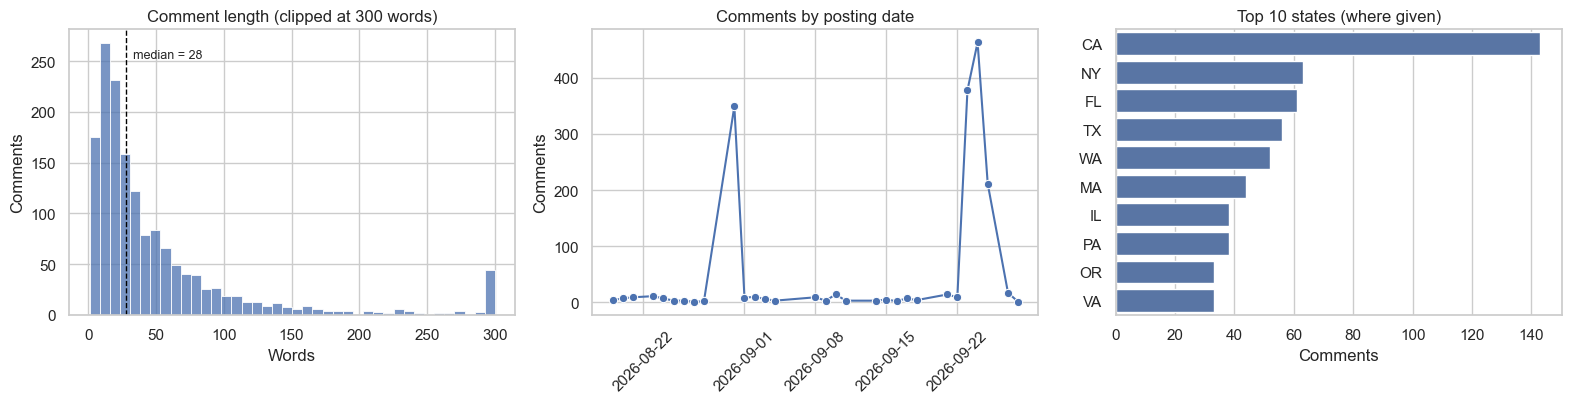

In [129]:
# SUMMARY STATISTICS
# Describes the cleaned comments: how long they are, when they
# were posted and where commenters are from.

# Comment length
# Mean and median words, plus spread. A mean far above the median
# signals a few very long comments pulling the average up.
length = df["n_words"].describe(percentiles=[.25, .5, .75, .9]).round(1)
print("Words per comment:")
print(length.to_string(), "\n")

# Posting dates
print(f"Posted between {df['posted_date'].min()} and {df['posted_date'].max()}")
by_date = df.groupby("posted_date").size()
top3 = by_date.nlargest(3)
print(f"Busiest days: " + ", ".join(f"{d} ({n})" for d, n in top3.items()))
print(f"Share posted on the 3 busiest days: {top3.sum() / len(df):.0%}\n")

# Commenter location (optional field)
print(f"State given: {df['state'].notna().mean():.0%} of comments")
print("Top 5 states:", df["state"].value_counts().head(5).to_dict())

# Charts
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

# 1. Length distribution. Clipped at 300 words so the long tail of
#    a few very long comments does not squash the main shape.
sns.histplot(df["n_words"].clip(upper=300), bins=40, ax=axes[0], color="#4C72B0")
axes[0].axvline(df["n_words"].median(), color="black", ls="--", lw=1)
axes[0].set(title="Comment length (clipped at 300 words)", xlabel="Words", ylabel="Comments")
axes[0].text(df["n_words"].median() + 5, axes[0].get_ylim()[1] * 0.9,
             f"median = {df['n_words'].median():.0f}", fontsize=9)

# 2. Comments per posting date
sns.lineplot(x=pd.to_datetime(by_date.index), y=by_date.values, marker="o", ax=axes[1], color="#4C72B0")
axes[1].set(title="Comments by posting date", xlabel="", ylabel="Comments")
axes[1].tick_params(axis="x", rotation=45)

# 3. Top 10 states
top_states = df["state"].value_counts().head(10)
sns.barplot(x=top_states.values, y=top_states.index, ax=axes[2], color="#4C72B0")
axes[2].set(title="Top 10 states (where given)", xlabel="Comments", ylabel="")

plt.tight_layout()
plt.savefig(FIG / "summary_statistics.png", dpi=150, bbox_inches="tight")
plt.show()

### What the summary statistics show

- **Comments are short and review-like.** The median comment is 28 words; half are between 14 and 59 words, and 90% are under 120 words. A small number of long comments (up to 820 words) pull the mean up to 56.5 words, so the median is the better summary. The bar at 300 in the chart gathers all comments over 300 words.
- **Short comments suit the classification task.** Most comments state one position in a few sentences, which should make them easier to label consistently, for humans and for the LLM. The 56 comments under 5 words (3.6%) are flagged in case they carry too little information.
- **Posting is concentrated on three days.** Comments were posted between August 19 (the day the proposal was published) and September 28. 76% were posted on just three days: September 24 (463), September 23 (378) and August 31 (349). `posted_date` records when the FTC published a comment online, not when it was submitted, so these spikes most likely reflect batch posting by the agency; organized campaigns may also contribute, which we check with near-duplicate detection next.
- **Commenters come from across the country.** 65% give a U.S. state. California leads (143), followed by New York (63), Florida (61), Texas (56) and Washington (52), broadly in line with state populations.
- **Commenters are self-selected.** People choose whether to comment, so these results describe *commenters*, not the U.S. public. All findings are worded accordingly.

### 4.2 Word cloud: the most frequent words

A word cloud shows the words commenters use most, sized by frequency. The words every comment shares (*pricing*, *price*, *personalized*, *surveillance*) are removed, otherwise they would fill the picture and hide everything else. It is a quick visual overview for the reader; the topic model in Section 6 is the systematic version of the same idea.

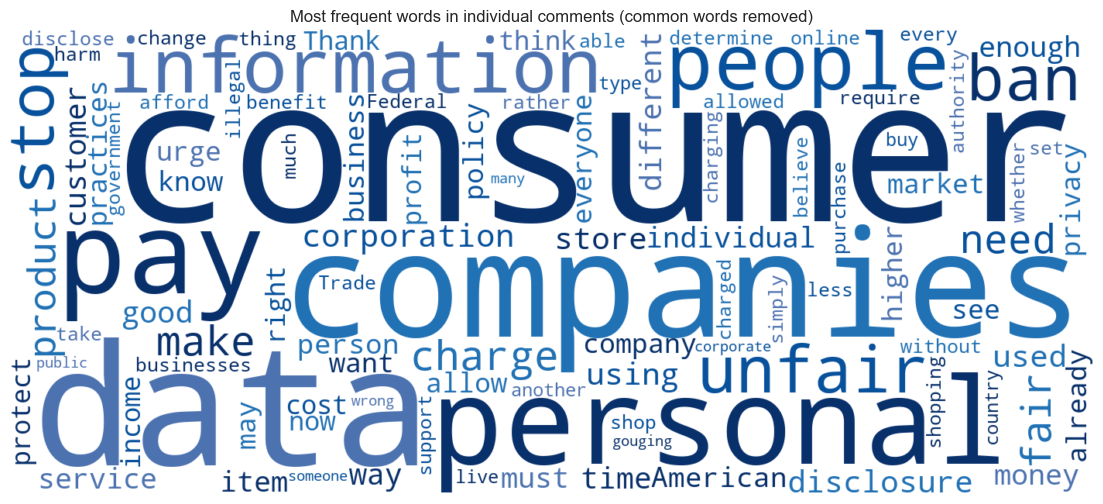

Top 15 words (relative frequency, 1 = most frequent):
consumer       1.00
data           0.65
companies      0.50
personal       0.45
pay            0.42
people         0.38
information    0.35
unfair         0.25
stop           0.24
ban            0.23
charge         0.23
make           0.23
fair           0.22
need           0.21
product        0.20


In [130]:
# WORD CLOUD
# Shows the most frequent words across all comments, sized by how often they
# appear. Common English words and the words almost every comment shares are
# removed so that the more informative words become visible.
# Requires the 'wordcloud' package: pip install wordcloud
from wordcloud import WordCloud, STOPWORDS

# 1. Words to leave out: standard English stopwords, plus words that appear in
# nearly every comment and would dominate the picture without telling us anything
DOMAIN_WORDS = {"pricing", "price", "prices", "personalized", "surveillance", "ftc", "commission",
                "will", "s", "t", "us", "one", "also", "even", "get", "please", "practice", "based", "use"}
stop = STOPWORDS | DOMAIN_WORDS

# 2. Build the word cloud from all cleaned comment text.
# random_state fixes the layout, so the picture is the same on every run.
# color_func picks one of four dark blues at random, so every word stays readable
dark_blues = ["#08306B", "#08519C", "#2171B5", "#4C72B0"]
rng = np.random.default_rng(SEED)
cloud = WordCloud(width=1400, height=600, background_color="white", stopwords=stop, max_words=100,
                  color_func=lambda *args, **kwargs: dark_blues[rng.integers(len(dark_blues))],
                  random_state=SEED, collocations=False).generate(" ".join(df["text"]))

# 3. Show and save it
fig, ax = plt.subplots(figsize=(12, 5.2))
ax.imshow(cloud, interpolation="bilinear")
ax.axis("off")
ax.set_title("Most frequent words in individual comments (common words removed)", fontsize=12)
plt.tight_layout()
plt.savefig(FIG / "word_cloud.png", dpi=150, bbox_inches="tight")
plt.show()

# 4. The top 15 words as numbers, for the report (the picture alone is hard to quote)
top_words = pd.Series(cloud.words_).head(15)
print("Top 15 words (relative frequency, 1 = most frequent):")
print(top_words.round(2).to_string())

**How to read the word cloud.** Bigger words appear more often. The picture is dominated by **consumer**, **data** and **personal** (the privacy concern), **companies** and **people**, **pay** and **charge** (what people are asked to pay), and words of judgement and demand such as **unfair**, **stop** and **ban**. It previews the main reasons the coding dictionary captures: privacy, equal treatment and fairness. Word clouds count words without context ("not fair" and "fair" both add to *fair*), so they illustrate themes but are not evidence on their own.

## 5. Form letters (near-duplicate comments)

In [131]:
# NEAR-DUPLICATE (FORM-LETTER) DETECTION
# Organized campaigns can submit many near-identical comments,
# which would inflate one position in the results. We flag them
# (not delete them) and later report findings with and without them.

DUP_THRESHOLD = 0.80   # two comments this similar or more count as near-duplicates

# 1. Turn each comment into a word-weight vector (TF-IDF)
# Common English words are ignored; word pairs (bigrams) capture phrasing.
X = TfidfVectorizer(stop_words="english", ngram_range=(1, 2)).fit_transform(df["text"])

# 2. Compare every comment with every other (cosine similarity, 0 to 1)
sim = cosine_similarity(X)
np.fill_diagonal(sim, 0)          # ignore each comment's similarity to itself

#  3. Group comments linked by high similarity
# If A ~ B and B ~ C, all three join one group (one "form letter").
_, groups = connected_components(csr_matrix(sim >= DUP_THRESHOLD), directed=False)
df["dup_group"] = groups
df["dup_group_size"] = df.groupby("dup_group")["comment_id"].transform("size")
df["is_near_duplicate"] = df["dup_group_size"] > 1

# Keep one comment per group as its representative, for the sensitivity check later.
df["is_group_representative"] = ~df.duplicated("dup_group")

# 4. Report
n_dup = df["is_near_duplicate"].sum()
n_groups = df.loc[df["is_near_duplicate"], "dup_group"].nunique()
print(f"Near-duplicates: {n_dup} comments ({n_dup / len(df):.1%}) in {n_groups} groups")
print(f"Comments after keeping one per group: {df['is_group_representative'].sum():,}\n")

print("Largest groups (one example each):")
largest = (df[df["dup_group_size"] >= 3]
           .drop_duplicates("dup_group")
           .sort_values("dup_group_size", ascending=False)
           .head(5))
for _, r in largest.iterrows():
    print(f"  {r['dup_group_size']} comments | {r['text'][:110]!r}")

Near-duplicates: 59 comments (3.8%) in 22 groups
Comments after keeping one per group: 1,529

Largest groups (one example each):
  5 comments | 'No more surveillance pricing!!!'
  4 comments | 'This is not fair!!!'
  4 comments | 'Please stop personalized pricing NOW'
  4 comments | 'One price for everyone!'
  4 comments | 'From groceries to gas, the cost of necessities is continuing to skyrocket. During this time of economic stress'


### What do we find from Form letters detection?

- **59 comments (3.8%) are near-duplicates**, in 22 groups (TF-IDF cosine similarity ≥ 0.80). Keeping one comment per group leaves 1,529.
- **Most groups are short slogans**, such as "No more surveillance pricing!!!" (5 comments) and "One price for everyone!" (4). Identical short phrases can be written independently, so these are not necessarily coordinated.
- **One group is a campaign template**: "From groceries to gas, the cost of necessities is continuing to skyrocket…" (4 comments).
- **Implication.** Coordinated campaigns are a small share of this sample, so they are unlikely to drive the results. As a sensitivity check, key findings are also reported using one comment per group. The posting-date spikes in Section 4 are therefore not mainly form letters, consistent with batch posting by the agency.

## 6. Exploratory NLP. Topic modelling (what themes appear on their own?)

Before designing the labels the LLM will assign, we look at the comments bottom-up with two classic methods: **topic modelling**, to see which themes emerge without being told what to look for, and **sentiment analysis**, as a baseline to test whether tone can stand in for a commenter's position.

In [132]:
# TOPIC MODELLING (NMF on TF-IDF)
# Finds groups of words that tend to appear together. Each group
# is a "topic". Used to check that our label categories (codebook)
# cover the themes commenters actually raise.
K_TOPICS = 8   # number of topics; 8 gave distinct, readable themes

# 1. Word weights for each comment
# min_df=5: ignore words used in fewer than 5 comments (too rare to form a theme)
# max_df=0.6: ignore words in over 60% of comments (too common to separate themes)
vec = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=5, max_df=0.6)
X_topics = vec.fit_transform(df["text"])
terms = np.array(vec.get_feature_names_out())

# 2. Fit the topic model
# NMF splits the comment-word matrix into topics. random_state fixes the result.
nmf = NMF(n_components=K_TOPICS, random_state=SEED, init="nndsvda", max_iter=500)
weights = nmf.fit_transform(X_topics)

# 3. Assign each comment its strongest topic
df["topic"] = weights.argmax(axis=1)

# 4. Show each topic's top words and size
for k, comp in enumerate(nmf.components_):
    top_words = ", ".join(terms[comp.argsort()[::-1][:8]])
    n = (df["topic"] == k).sum()
    print(f"Topic {k} ({n} comments, {n / len(df):.0%}): {top_words}")

Topic 0 (164 comments, 10%): personal, data, personal data, use, companies, using, information, use personal
Topic 1 (215 comments, 14%): surveillance pricing, surveillance, pricing, ban, ban surveillance, unfair, ftc, pricing unfair
Topic 2 (254 comments, 16%): personalized, personalized pricing, pricing, stop personalized, allow, unfair, consumer, illegal
Topic 3 (188 comments, 12%): price, price gouging, gouging, price price, item, price item, pay, consumers
Topic 4 (98 comments, 6%): stop, stop personalized, stop surveillance, needs, practice, pricing stop, invasion, unfair
Topic 5 (73 comments, 5%): commission, consumers, urge, ftc, disclose, companies disclose, merely, authority
Topic 6 (384 comments, 25%): people, just, money, corporations, pay, way, make, don
Topic 7 (190 comments, 12%): different, prices, fair, different prices, based, charge, charge different, product


### Insights

An 8-topic NMF model groups the comments into themes that match the coding dictionary's categories:

- **Privacy and data use**: Topic 0, "personal data" (10%).
- **Calls for a ban**: Topic 1, "ban surveillance pricing" (14%); Topic 2, "stop / illegal" (16%); Topic 4, short "stop it" demands (6%); and Topic 5, a campaign-style argument that disclosure is not enough and the FTC should use its full authority (5%).
- **Prices, gouging and corporations**: Topic 3, "price gouging" (12%), and Topic 6, general frustration about money and corporations (25%, the broadest topic).
- **Equal treatment**: Topic 7, "different prices for different people" (12%).

**What topics can and cannot tell us.** Topics show *what* people talk about, not *what they want*: a comment can ask for a ban in many ways, and Topic 6 mixes several concerns. Topic modelling therefore informs the coding dictionary but cannot replace a classifier that reads each comment's position.

**Dictionary implication.** The themes line up with the dictionary's reason categories (privacy, pricing and equal treatment, fairness and consumer harm, transparency). No topic covers legal or business arguments, which are rare among individuals; the dictionary keeps those categories so that rare but policy-relevant arguments are not lost.

### Naming the topics and linking them to the coding dictionary

The topic model only outputs numbered word lists. This step does three things:

1. **Names each topic** in plain English from its top words, so the themes are readable in the report and slides.
2. **Maps each topic to the dictionary**: to the closest **reason** category, and to a **stance** (ban-related topics map to `stronger_action`, all others to `unclear`, because word patterns alone rarely reveal what a commenter wants).
3. **Charts the share of comments in each theme.**

The mapping turns topic modelling into a simple **baseline classifier**. In Section 8 we score it against the human gold standard, alongside Claude, to measure whether the LLM adds accuracy over a classic method.

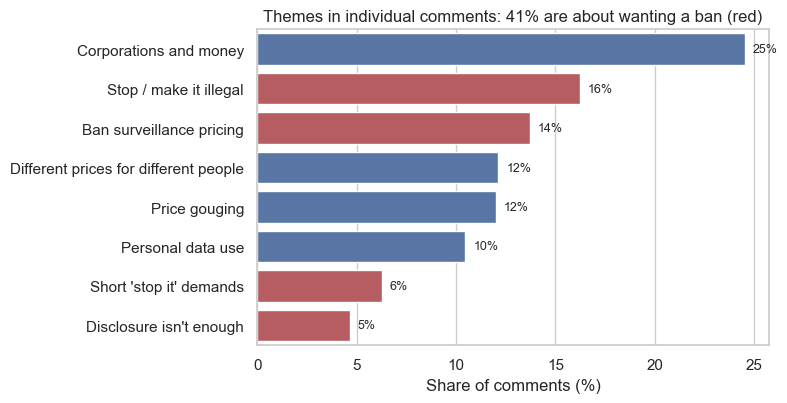

In [133]:
# NAME THE TOPICS AND LINK THEM TO THE CODING DICTIONARY
# The topic model only outputs numbered word lists. Here we give each topic
# a plain-English name, link it to the dictionary's labels so it can act as
# a simple baseline classifier (scored in Section 8), and chart the themes.

# 1. Plain-English names, chosen from each topic's top words (printed above)
TOPIC_NAMES = {
    0: "Personal data use",
    1: "Ban surveillance pricing",
    2: "Stop / make it illegal",
    3: "Price gouging",
    4: "Short 'stop it' demands",
    5: "Disclosure isn't enough",
    6: "Corporations and money",
    7: "Different prices for different people",
}

# 2. The closest reason category for each topic.
# None means the topic states a demand ("ban it") rather than a reason,
# so the baseline gives those comments no reason.
TOPIC_TO_REASON = {
    0: "privacy_data_use",
    1: None,
    2: None,
    3: "pricing_affordability_equal_treatment",
    4: None,
    5: "transparency_disclosure",
    6: "fairness_discrimination_consumer_harm",
    7: "pricing_affordability_equal_treatment",
}

# 3. Topics about wanting a ban count as stance 'stronger_action';
# every other topic says why people object but not what they want -> 'unclear'
BAN_TOPIC_IDS = [1, 2, 4, 5]

# 4. Add the names and the baseline predictions to every comment
df["topic_name"] = df["topic"].map(TOPIC_NAMES)
df["topic_reason"] = df["topic"].map(TOPIC_TO_REASON)                                          # baseline reason
df["topic_stance"] = np.where(df["topic"].isin(BAN_TOPIC_IDS), "stronger_action", "unclear")   # baseline stance
assert df["topic_name"].notna().all(), "Every comment must have a named topic"

# 5. Chart: share of comments whose main theme is each topic.
# Largest theme on top; the four ban-related topics are red, because together
# they show how many commenters ask the FTC to go further than disclosure.
BAN_TOPICS = {TOPIC_NAMES[k] for k in BAN_TOPIC_IDS}
topic_share = df["topic_name"].value_counts(normalize=True).sort_values(ascending=False) * 100
colors = ["#C44E52" if name in BAN_TOPICS else "#4C72B0" for name in topic_share.index]

fig, ax = plt.subplots(figsize=(8, 4.2))
sns.barplot(x=topic_share.values, y=topic_share.index, palette=colors, hue=topic_share.index,
            legend=False, ax=ax)
for i, v in enumerate(topic_share.values):
    ax.text(v + 0.4, i, f"{v:.0f}%", va="center", fontsize=9)          # percentage label next to each bar
ban_total = topic_share[topic_share.index.isin(BAN_TOPICS)].sum()
ax.set(title=f"Themes in individual comments: {ban_total:.0f}% are about wanting a ban (red)",
       xlabel="Share of comments (%)", ylabel="")
plt.tight_layout()
plt.savefig(FIG / "topics.png", dpi=150, bbox_inches="tight")
plt.show()

**How to read this chart.** The topic model grouped words that tend to appear together into eight themes and placed each comment in the one theme it matches best. Each bar shows the **percentage of comments whose main theme** is that one; the bars add up to 100%.

- **Red bars** are themes where commenters **ask for the practice to be stopped or banned**: "Stop / make it illegal" (16%), "Ban surveillance pricing" (14%), short "stop it" demands (6%), and "Disclosure isn't enough" (5%). Together they cover **41% of comments**.
- **Blue bars** are themes about **why** commenters object: frustration with corporations and the cost of living (25%), unequal prices for the same product (12%), price gouging (12%), and the use of personal data (10%).

**Takeaway.** About four in ten commenters focus on demanding a ban; the rest mostly explain their objection through corporate behavior, unequal prices, or the use of their personal data.

**Caveat.** Topics are built from word patterns, not meaning, and each comment counts in only one theme even if it raises several. These shares are a first look; the validated estimates come from the LLM labels in Section 9.

## 7. Modelling

**Goal.** Label each comment with **what the commenter wants the FTC to do** (stance) and **the reasons they give** (one or more), accurately enough that the labels can be trusted for business findings.

**Approach.** We compare four models, from simplest to most capable:

1. **Sentiment baseline (VADER):** a free, dictionary-based tool that scores tone. Tests whether tone alone reveals what a commenter wants.
2. **Topic baseline:** each comment gets the stance and reason linked to its main topic (Section 6). Tests whether word patterns alone are enough.
3. **Supervised baseline (TF-IDF + logistic regression):** a classic text classifier trained on the human-labeled comments, scored by cross-validation. Tests what a traditional machine-learning approach achieves with the same labels.
4. **LLM classifier (Claude):** reads each comment and applies the coding dictionary, returning structured labels with a supporting quote.

**Why baselines.** An LLM costs money and adds risk. It is only worth using if it clearly beats cheaper methods, so every model is scored against the same human gold standard in Section 8.

### 7.1 Baseline 1: sentiment (VADER)

Sentiment analysis scores how positive or negative a text sounds. If tone could stand in for what a commenter wants, a simple, free sentiment tool would be enough and an LLM would be unnecessary. We test that here.

VADER sentiment labels:
vader_label
negative    55.9%
positive    32.1%
neutral     12.0%
Name: proportion, dtype: str 

Comments VADER rates most positive:
  - Public Comment Submission Docket ID: FTC-2026-1057  Re: Proposed Enforcement Policy Statement Regarding Personalized Pricing  Submitter: [NAME] / Concerned Consumer  I. The Best-Ca
  - I strongly support greater consumer protections against personalized pricing based on personal data.  Technology should make markets more competitive and transparent for consumers.
  - I am writing as both a consumer and a small-business attorney who regularly advises businesses regarding online transactions, disclosures, privacy, and consumer-facing practices. I
  - All prices should be the same for everybody, no matter how they look, how they dress, what brand is their car ,or i9f they have 2 $8,000 frenchies, or a street cat. This should be 
  - I strongly support the Federal Trade Commission taking a strong enforcement position against decept

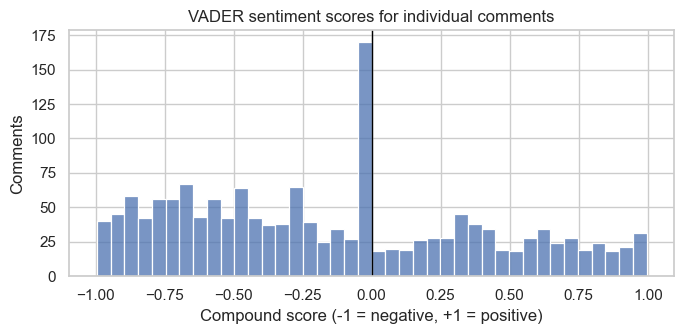

In [134]:
# VADER is a dictionary-based sentiment tool: it scores text from
# -1 (very negative) to +1 (very positive) by looking up words.
# We test whether tone matches what commenters actually think.

analyzer = SentimentIntensityAnalyzer()

# 1. Score each comment
# "compound" is VADER's overall score for the whole text.
df["vader_score"] = df["text"].map(lambda t: analyzer.polarity_scores(t)["compound"])

# 2. Convert scores to labels, using VADER's standard cut-offs
df["vader_label"] = pd.cut(df["vader_score"], bins=[-1.01, -0.05, 0.05, 1.01],
                           labels=["negative", "neutral", "positive"])

# 3. How are comments distributed?
print("VADER sentiment labels:")
print(df["vader_label"].value_counts(normalize=True).mul(100).round(1).astype(str) + "%", "\n")

# 4. Read the comments VADER rates most POSITIVE
# Some commenters type their own name into the text (e.g., "Submitter: ...").
# Mask common self-identification patterns before printing (privacy rule).
def mask_names(t):
    t = re.sub(r"(?i)(submitter|submitted by|name|sincerely|regards|respectfully)\s*[:,]?\s*[A-Z][\w.\-]*(\s+[A-Z][\w.\-]*){0,3}",
               r"\1: [NAME]", t)
    return t

print("Comments VADER rates most positive:")
for t in df.sort_values("vader_score", ascending=False)["text"].head(5):
    print("  -", mask_names(t).replace("\n", " ")[:180])

# 5. Chart: histogram of tone scores (bars left of the black line are negative)
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(df["vader_score"], bins=40, color="#4C72B0", ax=ax)
ax.axvline(0, color="black", lw=1)
ax.set(title="VADER sentiment scores for individual comments",
       xlabel="Compound score (-1 = negative, +1 = positive)", ylabel="Comments")
plt.tight_layout()
plt.savefig(FIG / "vader_sentiment.png", dpi=150, bbox_inches="tight")
plt.show()

**How to read this chart.** VADER gives each comment a score from −1 (very negative tone) to +1 (very positive tone). Each bar counts the comments with scores in that range; the black line marks a neutral score of 0.

**What it shows.** 56% of comments score negative, 32% positive and 12% neutral. The tall bar at 0 is mostly very short comments with no emotional words, such as "One price for everyone!".

**Why this matters: tone is not position.** Reading the comments VADER rates *most positive* shows they all oppose personalized pricing, for example: *"I strongly support greater consumer protections against personalized pricing based on personal data."* VADER scores words like "support", "protections" and "fair" as positive, even when they are used to demand stronger regulation. A third of commenters would be misread as positive if tone were used as a stand-in for their position.

**Takeaway.** A cheap sentiment tool cannot tell us what commenters want, which is why we need a classifier that reads each comment against defined categories. In Section 8 we measure this gap by scoring VADER against the human gold standard (negative tone → `stronger_action`, positive → `support_as_proposed`, neutral → `unclear`).

### 7.2 Baseline 2: topics as a classifier

The topic model from Section 6 can be used as a simple classifier: each comment gets the stance and reason linked to its main topic (columns `topic_stance` and `topic_reason`). It needs no labels and no API, so it is a natural low-cost baseline. Its weakness is already visible: ban-related topics say what commenters *want* but not *why*, and every other topic says *why* but not *what they want*. Section 8 scores this baseline against the gold standard.

### 7.3 Baseline 3: supervised classifier (TF-IDF + logistic regression)

A traditional classifier learns from labeled examples: it turns each comment into word and word-pair weights (TF-IDF, as in Section 5) and fits a logistic regression to predict the stance. It needs the human labels, so it is trained and scored on the gold set using **cross-validation**: the gold comments are split into folds, and each fold is predicted by a model trained on the others, so no comment is scored by a model that saw it. Class weights are balanced so rare stances are not ignored. It is defined here and run in Section 8.

In [135]:
# SUPERVISED BASELINE: TF-IDF + LOGISTIC REGRESSION
# A traditional machine-learning classifier, used as the strongest
# "non-GenAI" comparison for Claude. It learns from the human labels, so
# it is only defined here and is trained and scored in Section 8.
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, cross_val_predict

def tfidf_logreg_cv(texts, labels, n_folds=5):
    """Predicts the stance of every gold comment using cross-validation.

    How it works:
    - TF-IDF turns each comment into word and word-pair weights (as in Section 5);
      words used in fewer than 2 comments are ignored.
    - Logistic regression learns which words go with which stance.
      class_weight='balanced' stops it from ignoring rare stances.
    - Cross-validation: the comments are split into 5 folds; each fold is
      predicted by a model trained on the other 4, so no comment is ever
      predicted by a model that has seen its label (a fair test).
    """
    model = make_pipeline(
        TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2),
        LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED),
    )
    folds = KFold(n_splits=n_folds, shuffle=True, random_state=SEED)   # fixed seed = same folds every run
    return cross_val_predict(model, texts, labels, cv=folds)

print("Supervised baseline defined (runs in Section 8).")

Supervised baseline defined (runs in Section 8).


### 7.4 The coding dictionary: what the models must predict

The coding dictionary defines the labels, so human coders and Claude classify the same things by the same rules. It was developed by the team through a 40-comment development pilot, which tested and tightened the category boundaries, and is documented in full, with boundary rules and worked examples, in `CODEBOOK.md`. Its key design choices:

- **Stance asks what the commenter wants the FTC to do**, not how they feel. Many commenters dislike personalized pricing but want different responses: a ban, the proposed disclosure rules, exemptions, or less intervention. A negative comment is not automatically a request for action.
- **Exactly one stance per comment**, chosen with explicit tie-breaking rules (for example, a direct request for a ban overrides generic praise for the FTC).
- **Zero or more reasons per comment**, because many comments combine arguments (for example, privacy and unequal prices). A reason is coded only if it passes the **substantive-reason test**: if the issue were removed, would one of the commenter's actual reasons disappear?

The dictionary is defined once below. The coding sheets, Claude's prompt and the evaluation all read from it.

In [136]:
# CODING DICTIONARY (v2)
# The single source of truth for the labels. The coding sheets,
# the LLM prompt and the evaluation all read from here.

# Stance: exactly one per comment
STANCE = {
    "stronger_action": "Supports FTC/government intervention but explicitly wants a materially stronger response than the "
                       "proposed disclosure/enforcement approach (ban or prohibit personalized pricing; 'disclosure is not "
                       "enough'; prohibit individualized markups; mandatory opt-in).",
    "support_as_proposed": "Broadly supports the FTC's proposed disclosure/enforcement approach and does not ask for a materially "
                           "stronger or narrower response (clear notice that a price is personalized; explain the basis and data used).",
    "limit_or_oppose_intervention": "Argues the FTC response goes too far, should be narrowed or not adopted, imposes unjustified "
                                    "burdens, or exceeds FTC authority.",
    "mixed_or_conditional": "Supports some intervention but draws a substantive boundary (for example, personalized discounts "
                            "acceptable but personalized markups should be prohibited).",
    "unclear": "The desired FTC/government response cannot be determined reliably (only says personalized pricing is "
               "bad or unfair; too little information; misunderstands the proposal with no recoverable desired action).",
}

# Reasons: zero or more per comment. Each entry: (code when..., do not code when...)
REASONS = {
    "privacy_data_use": ("Personal data collection or use is part of the argument: surveillance, tracking, profiling, consent, "
                         "browsing/location/purchase data, data brokers.",
                         "The comment merely mentions that an algorithm uses data."),
    "transparency_disclosure": ("Hidden or opaque personalized pricing, notice, disclosure, or explaining what affected the price.",
                                "The comment only repeats the proposal's disclosure requirement without endorsing or criticizing it."),
    "fairness_discrimination_consumer_harm": ("Exploitation, unfairness, discrimination, vulnerable consumers, necessities, "
                                              "inability to shop around, manipulation, or concrete consumer harm.",
                                              "Used as a catch-all for any negative comment; the harm logic must be stated."),
    "pricing_affordability_equal_treatment": ("The price outcome itself: different people paying different prices, individualized "
                                              "markups, affordability, gouging, equal or uniform pricing.",
                                              "Prices are mentioned without being part of the argument."),
    "competition_business_economics": ("A genuine market or economic argument: competition, market power, innovation, efficiency, "
                                       "business burden, benefits of discounts.",
                                       "Firms, profits or corporations are merely mentioned."),
    "legal_authority_policy_scope": ("FTC authority, Section 5, jurisdiction, constitutionality, statutory limits, or which "
                                     "sectors or practices should be covered or exempt.",
                                     "The comment only says 'the FTC should act' or 'use its authority'."),
    "other": ("A substantive policy reason that does not fit any category above.",
              "The comment is vague; if no reason is expressed, code no reason."),
}

# Boundary and tie-breaking rules (used in the coding instructions and the prompt)
RULES = [
    "A direct request for a ban or materially stronger restriction overrides generic praise for the FTC -> stronger_action.",
    "Support for disclosure/enforcement plus minor implementation suggestions remains support_as_proposed.",
    "A genuine carve-out or two-sided position (discounts yes, individualized markups no) -> mixed_or_conditional.",
    "Use limit_or_oppose_intervention only when the commenter wants less or narrower FTC intervention. "
    "Disliking personalized pricing is not opposition to the FTC.",
    "If the commenter misunderstands the proposal and the desired response is not otherwise clear -> unclear.",
    "Tone does not determine stance. Anger or words such as 'unfair' are not stance labels by themselves.",
    "Saying personalized pricing is unfair or wrong is not automatically a request for action; direct requests to ban, "
    "stop, protect consumers or strengthen the remedy count as stronger_action.",
    "Substantive-reason test: code a reason only if removing that issue would remove one of the commenter's actual reasons.",
    "If a comment gets four or more reasons, reread it and check every reason passes the substantive-reason test.",
]

# Lists of the label names, used for dropdowns, the prompt and the scoring
STANCE_LABELS = list(STANCE)
REASON_LABELS = list(REASONS)

# Checks: labels are unique and every reason has both a 'code when' and a 'do not code when' rule
assert len(set(STANCE_LABELS)) == len(STANCE_LABELS) == 5
assert len(set(REASON_LABELS)) == len(REASON_LABELS) == 7
assert all(len(v) == 2 and all(v) for v in REASONS.values())
print("Stance labels:", STANCE_LABELS)
print("Reason labels:", REASON_LABELS)

Stance labels: ['stronger_action', 'support_as_proposed', 'limit_or_oppose_intervention', 'mixed_or_conditional', 'unclear']
Reason labels: ['privacy_data_use', 'transparency_disclosure', 'fairness_discrimination_consumer_harm', 'pricing_affordability_equal_treatment', 'competition_business_economics', 'legal_authority_policy_scope', 'other']


### 7.5 LLM classifier (Claude)

**Design choices.**
- **Model:** Claude Haiku 5.5 (`claude-haiku-5-5`), Anthropic's lowest-cost current model, suited to short, high-volume classification. The current Anthropic API (version 2026-10-21, used by Python SDK 2.x) no longer accepts a `temperature` setting, so the model runs with default sampling; consistency is therefore **measured** with a stability test (8.6) rather than assumed, and supported by a strict JSON output format and an explicit codebook.
- **Prompt:** the full coding dictionary (definitions, tie-breaking rules, substantive-reason test), so Claude applies the same rules as the human coders. Claude must return JSON with the stance, the list of reasons, a short **verbatim quote** supporting the stance, and its confidence.
- **Two variants, compared in Section 8:** *zero-shot* (dictionary only) and *few-shot* (dictionary plus the 20 agreed pilot examples). Pilot examples are never taken from the gold set, so the test stays fair.
- **Checks on every answer:** invalid JSON or a label outside the dictionary is marked `INVALID`; the evidence quote must actually appear in the comment, otherwise the answer is flagged. Flagged answers go to human review.
- **Privacy:** names that commenters typed into their text are masked before anything is sent to the API.
- **Cost and reproducibility:** every answer is saved with its token counts in `outputs/llm/`. Rerunning the notebook reuses saved answers instead of calling the API again, and costs are measured rather than estimated.

Below, the classifier is tested on 3 comments that are **not** in the hand-coding sample, so the coders never see AI labels for comments they will code.

In [137]:
# LLM CLASSIFIER (Claude)
# This cell builds the GenAI part of the workflow:
#   1. settings      - every choice about the model in one place
#   2. the prompt    - the coding dictionary turned into instructions
#   3. answer checks - catches broken or made-up answers
#   4. one API call  - sends one comment to Claude, with retries
#   5. many calls    - classifies a whole table, saving each answer
#   6. smoke test    - tries it on 3 comments to prove it works


# 1. SETTINGS
# All model choices live here so they can be reported and changed
# in one place.

# Load the API key from the private .env file. The key never appears
# in the notebook or on GitHub (.env is listed in .gitignore).
load_dotenv(ROOT / ".env")
assert os.environ.get("ANTHROPIC_API_KEY"), "No ANTHROPIC_API_KEY found in .env"

# Which model: Haiku 5.5 is Anthropic's lowest-cost current model,
# well suited to short, high-volume classification.
LLM_MODEL = "claude-haiku-5-5"

# Randomness: the current Anthropic API (version 2026-10-21) no longer
# accepts a temperature setting, so the model uses its default. Because
# we cannot force consistency, we measure it instead (stability test, 8.6).
SAMPLING = "API default"

# Thinking: Haiku 5.5 may reason ("think") before answering, and that
# reasoning is billed. Labeling a short comment needs little reasoning,
# so "low" effort keeps runs fast and cheap.
EFFORT = "low"

# Token limit for each answer. It must cover the thinking AND the short
# JSON answer, because thinking counts against this limit.
MAX_OUTPUT_TOKENS = 4096

# Prompt version: saved with every answer. If the prompt changes, bump
# this so old saved answers are not mixed with new ones.
PROMPT_VERSION = "v2"

# Prices (US dollars per million tokens), used for the cost analysis.
# Check your Anthropic console for the current figures.
PRICE_IN_PER_MTOK = 0.10
PRICE_OUT_PER_MTOK = 0.50

# Hand-coding sample sizes: 20 pilot + 80 gold comments (Section 8).
# Needed here so the smoke test can avoid those comments.
N_PILOT, N_GOLD = 20, 80

# Folder where every Claude answer is saved (the cache).
LLM_DIR = ROOT / "outputs" / "llm"
LLM_DIR.mkdir(parents=True, exist_ok=True)

# Connect to the Anthropic API using the key loaded above.
client = anthropic.Anthropic()


# 2. THE PROMPT
# Claude gets the same coding dictionary the human coders use, so
# humans and AI label the same things by the same rules. The prompt
# is built from STANCE, REASONS and RULES (Section 7.4), so a change
# to the dictionary updates the prompt automatically.
SYSTEM_PROMPT = (
    # Context: what the comments are about, and what the proposal does
    "You classify public comments sent to the U.S. Federal Trade Commission (FTC) about its proposed enforcement "
    "policy on personalized pricing (prices set using a consumer's personal data). The proposal does NOT ban "
    "personalized pricing: it says undisclosed or misleading personalization may be unlawful and emphasizes clear "
    "disclosure that a price is personalized, why, and what data were used.\n\n"
    # Stance: one label, with every definition written out
    "STANCE: ask 'What does this commenter want the FTC/government to do?' Choose exactly one:\n"
    + "\n".join(f"- {k}: {v}" for k, v in STANCE.items())
    # Reasons: zero or more, each with "code when" and "do not code when"
    + "\n\nREASONS: ask 'What substantive arguments does the commenter use to justify that position?' "
    "Choose zero or more:\n"
    + "\n".join(f"- {k}: code when: {c} Do not code when: {d}" for k, (c, d) in REASONS.items())
    # Tie-breaking and boundary rules
    + "\n\nRULES:\n" + "\n".join(f"- {r}" for r in RULES)
    # Required answer format: JSON only, so it can be checked automatically
    + '\n\nReturn ONLY a JSON object, with no other text:\n'
      '{"stance": "<one stance label>", "reasons": ["<zero or more reason labels>"], '
      '"evidence_quote": "<up to 20 words copied exactly from the comment that best supports the stance>", '
      '"confidence": "<low, medium or high>"}'
)


def few_shot_block(examples):
    """For the few-shot version: adds worked examples to the prompt.
    The examples come from the 20 agreed PILOT comments only, never the
    gold set, so Claude is never shown the answers it is scored on."""
    lines = ["\n\nEXAMPLES OF CORRECTLY LABELED COMMENTS:"]
    for _, r in examples.iterrows():
        labels = {"stance": r["stance"], "reasons": sorted(r["reasons"])}
        lines.append(f"\nCOMMENT: {r['text']}\nLABELS: {json.dumps(labels)}")
    return "\n".join(lines)


# 3. ANSWER CHECKS
# Every answer is checked before it is used. Problems are FLAGGED,
# never silently fixed, so flagged answers can go to human review.
def normalize(t):
    """Lower-case text with single spaces, for comparing quotes with comments."""
    return re.sub(r"\s+", " ", str(t)).strip().lower()

def parse_answer(raw, comment_text):
    """Reads Claude's answer and returns the labels plus quality flags:
    - parse_error:          the answer was not valid JSON
    - stance 'INVALID':     the stance is not one of the 5 dictionary labels
    - invalid_reason_label: a reason is not one of the 7 dictionary labels
    - quote_found:          the evidence quote really appears in the comment
                            (catches made-up quotes)"""
    # Start from a 'failed' answer; fields are filled in only if they check out
    out = {"stance": "INVALID", "reasons": [], "evidence_quote": "", "confidence": "low",
           "parse_error": False, "invalid_reason_label": False, "quote_found": False}

    # Find the JSON object in the answer and read it
    try:
        ans = json.loads(re.search(r"\{.*\}", raw, re.S).group(0))
    except Exception:
        out["parse_error"] = True
        return out

    # Stance must be a dictionary label
    out["stance"] = ans.get("stance") if ans.get("stance") in STANCE else "INVALID"

    # Reasons: keep only dictionary labels, and flag any made-up ones
    reasons = ans.get("reasons") or []
    reasons = reasons if isinstance(reasons, list) else [reasons]
    out["invalid_reason_label"] = any(r not in REASONS for r in reasons)
    out["reasons"] = sorted({r for r in reasons if r in REASONS})

    # Confidence must be low, medium or high (anything else counts as low)
    out["evidence_quote"] = str(ans.get("evidence_quote", ""))
    out["confidence"] = ans.get("confidence") if ans.get("confidence") in ("low", "medium", "high") else "low"

    # The quote must be copied from the comment, not invented
    quote = normalize(out["evidence_quote"]).strip(" .\"'")
    out["quote_found"] = bool(quote) and quote in normalize(comment_text)
    return out


# 4. ONE API CALL
# Sends one comment to Claude and returns its answer plus usage data
# (tokens, time) for the cost analysis.
def classify_one(text, system):
    global EFFORT
    for attempt in range(4):                        # up to 4 tries
        try:
            t0 = time.time()                        # start the timer (latency)

            # Build the request: model, token limit, prompt, and the comment
            kwargs = dict(model=LLM_MODEL, max_tokens=MAX_OUTPUT_TOKENS, system=system,
                          messages=[{"role": "user", "content": f"COMMENT:\n{text}"}])
            if EFFORT:
                kwargs["output_config"] = {"effort": EFFORT}
            r = client.messages.create(**kwargs)

            # Claude may return a 'thinking' block before its answer:
            # keep only the text blocks, which contain the JSON answer
            answer = "".join(b.text for b in r.content if getattr(b, "type", "") == "text")

            # How many output tokens were thinking (billed, so logged for cost)
            details = getattr(r.usage, "output_tokens_details", None)
            thinking = getattr(details, "thinking_tokens", 0) or 0

            return {"raw": answer, "input_tokens": r.usage.input_tokens, "output_tokens": r.usage.output_tokens,
                    "thinking_tokens": thinking, "stop_reason": r.stop_reason, "effort": EFFORT,
                    "latency_s": round(time.time() - t0, 2)}

        # If this account does not accept the effort setting, drop it
        # and use the model's default instead, then try again
        except anthropic.BadRequestError as e:
            if EFFORT and "effort" in str(e).lower():
                print(f"  effort='{EFFORT}' not accepted ({e}); using the model's default effort instead")
                EFFORT = None
                continue
            raise

        # Temporary problems (too many requests, network, server): wait longer
        # each time (10s, 20s, 30s...) and try again
        except (anthropic.RateLimitError, anthropic.APIConnectionError, anthropic.InternalServerError) as e:
            wait = 10 * (attempt + 1)
            print(f"  temporary API error ({type(e).__name__}), retrying in {wait}s")
            time.sleep(wait)
    raise RuntimeError("API failed 4 times in a row")


# 5. MANY CALLS, WITH A CACHE
# Classifies every comment in a table. Each answer is saved to a file
# in outputs/llm/ the moment it arrives, so:
#   - a crash loses nothing (rerun and it continues where it stopped)
#   - no comment is ever sent, or paid for, twice
#   - the notebook can be rerun later without calling the API at all
def classify(data, variant, examples=None):
    # One cache file per version (e.g. zero-shot, few-shot) and prompt version
    cache_file = LLM_DIR / f"labels_{variant}_{PROMPT_VERSION}.jsonl"

    # Load answers saved in earlier runs
    cache = {}
    if cache_file.exists():
        for line in cache_file.read_text(encoding="utf-8").splitlines():
            rec = json.loads(line)
            cache[rec["comment_id"]] = rec

    # The prompt: dictionary only (zero-shot), or plus pilot examples (few-shot)
    system = SYSTEM_PROMPT + (few_shot_block(examples) if examples is not None else "")

    # Only comments without a saved answer are sent to Claude
    todo = data[~data["comment_id"].isin(cache)]
    print(f"[{variant}] {len(data) - len(todo)} cached, {len(todo)} to classify")

    with cache_file.open("a", encoding="utf-8") as fh:
        for i, r in enumerate(todo.itertuples(), 1):
            # Privacy: mask names commenters typed into their text before sending
            text = mask_names(r.text)
            call = classify_one(text, system)

            # Save everything: identifiers, usage data, raw answer and checked labels
            rec = {"comment_id": r.comment_id, "variant": variant, "model": LLM_MODEL,
                   "prompt_version": PROMPT_VERSION} | call | parse_answer(call["raw"], text)
            fh.write(json.dumps(rec) + "\n")
            cache[r.comment_id] = rec

            # Progress message every 100 comments, and at the end
            if i % 100 == 0 or i == len(todo):
                print(f"  {i}/{len(todo)}")

    # Return one row per comment, in the same order as the input table
    result = pd.DataFrame([cache[c] for c in data["comment_id"] if c in cache])
    assert len(result) == len(data), f"[{variant}] some comments were not classified"
    return result


# 6. SMOKE TEST
# Runs the classifier on 3 comments to prove the setup works before
# spending on the full run. The 3 comments are deliberately chosen from
# OUTSIDE the hand-coding sample, so the coders never see AI labels for
# comments they will code themselves.

# The hand-coding sample (same random draw as Section 8.1)
coding_ids = set(df.sample(n=N_PILOT + N_GOLD, random_state=SEED)["comment_id"])

# 3 typical-length comments (15-60 words) not in that sample
test = df[~df["comment_id"].isin(coding_ids) & (df["n_words"].between(15, 60))].head(3)
result = classify(test, variant="smoketest")

# Show each comment with Claude's labels, so a person can sanity-check them
for (_, c), (_, lab) in zip(test.iterrows(), result.iterrows()):
    print("\nCOMMENT:", mask_names(c["text"])[:200].replace("\n", " "))
    print("STANCE: ", lab["stance"], "| REASONS:", lab["reasons"], "| confidence:", lab["confidence"])
    print("QUOTE:  ", lab["evidence_quote"], "| found in comment:", lab["quote_found"])

# Tokens and cost of the test, including how much was thinking
cost = (result["input_tokens"].sum() * PRICE_IN_PER_MTOK + result["output_tokens"].sum() * PRICE_OUT_PER_MTOK) / 1e6
print(f"\nTokens per comment: {result['input_tokens'].mean():.0f} in / {result['output_tokens'].mean():.0f} out"
      f" (of which thinking: {result['thinking_tokens'].mean():.0f}) | effort: {result['effort'].iloc[-1]}"
      f" | cost for 3 comments: ${cost:.5f}")

# Stop if an answer was cut off by the token limit, or was not valid JSON
assert (result["stop_reason"] != "max_tokens").all(), "An answer hit the token limit: raise MAX_OUTPUT_TOKENS"
assert not result["parse_error"].any(), "Some answers were not valid JSON"

[smoketest] 3 cached, 0 to classify

COMMENT: Company personal pricing should not be allowed using AI, financial data, web-based information, or other individual history.
STANCE:  stronger_action | REASONS: ['pricing_affordability_equal_treatment', 'privacy_data_use'] | confidence: high
QUOTE:   Company personal pricing should not be allowed using AI, financial data, web-based information, or other individual history. | found in comment: True

COMMENT: Personalized pricing is just unfair. It pits the rich vs the middle class vs the poor. Demand that companies abandon this practice.
STANCE:  stronger_action | REASONS: ['fairness_discrimination_consumer_harm', 'pricing_affordability_equal_treatment'] | confidence: medium
QUOTE:   Demand that companies abandon this practice. | found in comment: True

COMMENT: Life is difficult enough to have to worry about whether your shopping habits are costing you money! This is deliberate manipulation of the average person in favor of conglomerate mac

## 8. Evaluation

**Purpose.** Measure how accurately each model labels comments, using human judgment as the reference:

1. **Build a gold standard** (8.1–8.2): two team members label the same random comments independently, we measure their agreement (Cohen's kappa), and they resolve disagreements together.
2. **Run Claude on the gold comments** (8.3), zero-shot and few-shot.
3. **Score every model against the gold standard** (8.4–8.5): stance (one label) and reasons (several labels), with bootstrap 95% confidence intervals.
4. **Test reliability** (8.6–8.7): does Claude give the same answer twice, and does it perform equally well on short and long comments?
5. **Study the errors** (8.8).

**Thresholds are fixed here, before any results are seen**, so they cannot be adjusted to fit the results. Section 10 applies them.

In [138]:
# GOVERNANCE THRESHOLDS (fixed before evaluation)
# These are the measurable rules that decide whether Claude's labels can be
# trusted. They are written down BEFORE any results are seen, so they cannot
# be adjusted afterwards to make the results look good. Section 10 checks
# every result against them.

THRESHOLDS = {
    # Human reliability: coders must agree "substantially" on stance before
    # their labels are trusted as the gold standard
    "min_human_kappa": 0.60,
    # Model quality: scores Claude must reach for automatic reporting
    "min_stance_macro_f1": 0.70,        # stance macro-F1 over judged categories
    "min_stance_class_recall": 0.60,    # every judged stance must be found at least 60% of the time
    "min_reason_micro_f1": 0.70,        # overall reason extraction quality
    "min_class_support": 5,             # categories with fewer gold examples are shown but not judged
    # Output quality in production
    "max_low_confidence_share": 0.15,   # above this share of 'low' confidence answers, the batch goes to human review
    "max_invalid_share": 0.02,          # above this share of invalid answers, stop and fix the prompt
    "min_quote_found_share": 0.95,      # evidence quotes must be found word-for-word in the comment
    # Reliability over time and across comment types
    "min_stability": 0.90,              # same stance in all 3 runs for at least 90% of comments
    "max_length_error_ratio": 1.25,     # a length group with >1.25x the best group's error rate is investigated
    # Ongoing human oversight
    "audit_share": 0.05,                # 5% of every production run is re-checked by a person
}
N_BOOT = 2000         # bootstrap resamples used for every 95% confidence interval
STABILITY_N = 30      # gold comments re-run twice for the stability test (8.6)

# Every threshold that is a proportion must lie between 0 and 1
assert all(0 < v <= 1 for k, v in THRESHOLDS.items() if k not in ("min_class_support", "max_length_error_ratio"))
print("Thresholds fixed before evaluation:")
for k, v in THRESHOLDS.items():
    print(f"  {k}: {v}")

Thresholds fixed before evaluation:
  min_human_kappa: 0.6
  min_stance_macro_f1: 0.7
  min_stance_class_recall: 0.6
  min_reason_micro_f1: 0.7
  min_class_support: 5
  max_low_confidence_share: 0.15
  max_invalid_share: 0.02
  min_quote_found_share: 0.95
  min_stability: 0.9
  max_length_error_ratio: 1.25
  audit_share: 0.05


### 8.1 Hand-coding sample

- **100 comments**, drawn at random with the project seed (20261027), so the selection is reproducible and not cherry-picked.
- **Pilot (first 20):** both coders label them, compare, and agree on borderline cases. The agreed pilot labels become the worked examples in Claude's few-shot prompt; they are never used for scoring.
- **Gold set (remaining 80):** labeled independently, without discussion and without seeing any Claude labels. Agreement is measured, then disagreements are resolved to form the **gold standard**.
- Each coder has their own sheet: a dropdown for the stance and a yes/no column per reason. Names that commenters typed into their text are masked, since the sheets are stored in the public repository.

The gold set was sized at 80 to fit the project timeline (about 45–60 minutes of coding per person). The cost is wider confidence intervals, especially for rare categories, which we report.

In [139]:
# HAND-CODING SAMPLE AND CODING SHEETS
# Draws the random comments the two coders label by hand and creates one
# Excel sheet per coder, with dropdown menus built from the coding dictionary
# so only valid labels can be entered.
from openpyxl import Workbook
from openpyxl.worksheet.datavalidation import DataValidation
from openpyxl.styles import Font, PatternFill, Alignment

CODERS = ["coder1", "coder2"]   # one sheet per team member
CODING = ROOT / "coding"        # folder for everything about human labeling
CODING.mkdir(exist_ok=True)

# 1. Draw the sample: 100 comments at random with the project seed, so the
# same comments come out on every run (and the selection is not cherry-picked).
# The first 20 are the pilot round, the remaining 80 are the gold set.
sample = df.sample(n=N_PILOT + N_GOLD, random_state=SEED).copy()
sample["set"] = ["pilot"] * N_PILOT + ["gold"] * N_GOLD
sample["text_for_coding"] = sample["text"].map(mask_names)    # privacy: mask names typed into comments

# Checks: no repeated comments; the same comments 7.5 kept out of its smoke
# test; and none of the 3 smoke-test comments (whose AI labels were printed)
assert sample["comment_id"].is_unique and len(sample) == N_PILOT + N_GOLD
assert set(sample["comment_id"]) == coding_ids, "Sample differs from the one excluded in 7.5"
assert not set(sample["comment_id"]) & set(test["comment_id"]), "Smoke-test comments overlap the coding sample"

# Keep the two lists of IDs, and save the sample as a record (reproducibility)
pilot_ids = sample.loc[sample["set"] == "pilot", "comment_id"].tolist()
gold_ids = sample.loc[sample["set"] == "gold", "comment_id"].tolist()
sample[["comment_id", "set", "text_for_coding", "n_words"]].to_csv(CODING / "coding_sample.csv", index=False)
print(f"Sample: {N_PILOT} pilot + {N_GOLD} gold | median length {sample['n_words'].median():.0f} words")


# 2. Helper: add a dropdown list to a column of an Excel sheet.
# The allowed values are written on a hidden 'lists' sheet and linked to the column,
# so Excel refuses anything that is not on the list.
def add_dropdown(wb, ws, column_letter, options, n_rows, list_col, title):
    lists = wb["lists"] if "lists" in wb.sheetnames else wb.create_sheet("lists")
    lists[f"{list_col}1"] = title
    for i, opt in enumerate(options, start=2):
        lists[f"{list_col}{i}"] = opt
    dv = DataValidation(type="list", formula1=f"=lists!${list_col}$2:${list_col}${len(options) + 1}",
                        allow_blank=True, showErrorMessage=True, error="Pick a value from the list")
    ws.add_data_validation(dv)
    dv.add(f"{column_letter}2:{column_letter}{n_rows + 1}")
    lists.sheet_state = "hidden"


# 3. Helper: make a sheet easy to work in (coloured bold header, column widths,
# wrapped text so long comments are readable, header kept visible when scrolling)
def style_sheet(ws, widths, freeze="D2"):
    for cell in ws[1]:
        cell.font = Font(bold=True, color="FFFFFF")
        cell.fill = PatternFill("solid", fgColor="305496")
        cell.alignment = Alignment(wrap_text=True, vertical="top")
    for i, w in enumerate(widths):
        ws.column_dimensions[ws.cell(row=1, column=i + 1).column_letter].width = w
    for row in ws.iter_rows(min_row=2):
        for cell in row:
            cell.alignment = Alignment(wrap_text=True, vertical="top")
    ws.freeze_panes = freeze


# 4. Create one coding sheet per coder.
# Columns: the comment, a stance dropdown, one 'yes' column per reason, and notes.
# A sheet that already exists is never overwritten, so finished coding is safe.
SHEET_COLS = ["comment_id", "set", "text", "stance"] + REASON_LABELS + ["notes"]

def make_coding_sheet(coder):
    path = CODING / f"coding_sheet_{coder}.xlsx"
    if path.exists():
        print(f"{path.name} already exists, not overwritten")
        return
    wb = Workbook()
    ws = wb.active
    ws.title = "coding"
    ws.append(SHEET_COLS)
    for r in sample.itertuples():
        ws.append([r.comment_id, r.set, r.text_for_coding] + [None] * (len(SHEET_COLS) - 3))
    style_sheet(ws, [20, 7, 80, 24] + [14] * len(REASON_LABELS) + [30])
    add_dropdown(wb, ws, "D", STANCE_LABELS, len(sample), "A", "stance")      # stance: pick one
    for j, reason in enumerate(REASON_LABELS):                                # reasons: 'yes' or blank
        col = ws.cell(row=1, column=SHEET_COLS.index(reason) + 1).column_letter
        add_dropdown(wb, ws, col, ["yes"], len(sample), "B", "reason")
    wb.save(path)
    print(f"Created {path.name}")

for coder in CODERS:
    make_coding_sheet(coder)

Sample: 20 pilot + 80 gold | median length 24 words
coding_sheet_coder1.xlsx already exists, not overwritten
coding_sheet_coder2.xlsx already exists, not overwritten


**For the coders.** Each coder fills in only their own sheet (`coding/coding_sheet_coder1.xlsx` or `coding_sheet_coder2.xlsx`): pick one **stance** from the dropdown, and put **yes** under every reason that passes the substantive-reason test (leave the others blank). Use `CODEBOOK.md`. Code the 20 **pilot** rows first and compare; then code the 80 **gold** rows without discussing them, and without looking at any Claude labels.

In [140]:
# LOAD THE CODING SHEETS AND BUILD RECONCILIATION SHEETS
# Reads whatever the coders have finished. Once both coders are done with a
# set (pilot or gold), it creates a reconciliation sheet with their labels
# side by side: where they agree, the agreed label is filled in; where they
# disagree, it is left blank for the two coders to decide together.

# 1. Read one coder's sheet and check every label is valid
def load_coder(coder):
    """Rows a coder has finished (stance filled), with reasons as a set. None if no sheet yet."""
    path = CODING / f"coding_sheet_{coder}.xlsx"
    if not path.exists():
        return None
    sheet = pd.read_excel(path, sheet_name="coding")
    done = sheet.dropna(subset=["stance"]).copy()           # a row counts as coded once it has a stance

    # Stance must be one of the 5 dictionary labels
    bad = done.loc[~done["stance"].isin(STANCE_LABELS), "stance"]
    assert bad.empty, f"{coder}: invalid stance labels {bad.unique().tolist()}"

    # Reason columns may only contain 'yes' or be blank (catches typos like 'no' or '1')
    for reason in REASON_LABELS:
        marks = done[reason].dropna().astype(str).str.strip().str.lower()
        assert marks.isin(["yes"]).all(), f"{coder}: reason column {reason} must be 'yes' or blank"

    # Collect the reasons marked 'yes' into one set per comment
    done["reasons"] = done.apply(lambda r: frozenset(x for x in REASON_LABELS if str(r[x]).strip().lower() == "yes"), axis=1)
    assert set(done["comment_id"]) <= set(sample["comment_id"]), f"{coder}: comments outside the sample"
    return done[["comment_id", "set", "text", "stance", "reasons"]]


# 2. Have both coders finished every comment in a set?
def both_finished(sheets, ids):
    return all(s is not None and set(ids) <= set(s["comment_id"]) for s in sheets.values())


# 3. Write a set of reasons as text ("a; b", or "none") and read it back, with a check
def reasons_to_text(rs):
    return "; ".join(sorted(rs)) if rs else "none"

def text_to_reasons(t):
    t = str(t).strip()
    if t.lower() == "none":
        return frozenset()
    rs = frozenset(x.strip() for x in t.split(";") if x.strip())
    assert rs <= set(REASON_LABELS), f"Invalid reason label in reconciliation: {set(rs) - set(REASON_LABELS)}"
    return rs


# 4. Create the reconciliation sheet for a set (never overwritten once it exists)
def make_reconcile_sheet(sheets, ids, name):
    path = CODING / f"reconcile_{name}.xlsx"
    if path.exists():
        print(f"{path.name} already exists, not overwritten")
        return
    a, b = (sheets[c].set_index("comment_id").loc[ids] for c in CODERS)
    cols = ["comment_id", "text", f"stance_{CODERS[0]}", f"stance_{CODERS[1]}", "agreed_stance",
            f"reasons_{CODERS[0]}", f"reasons_{CODERS[1]}", "agreed_reasons"]
    wb = Workbook()
    ws = wb.active
    ws.title = "reconcile"
    ws.append(cols)
    n_open = 0
    for cid in ids:
        sa, sb, ra, rb = a.loc[cid, "stance"], b.loc[cid, "stance"], a.loc[cid, "reasons"], b.loc[cid, "reasons"]
        n_open += (sa != sb) or (ra != rb)
        # agreed_* is pre-filled only where both coders gave the same answer
        ws.append([cid, a.loc[cid, "text"], sa, sb, sa if sa == sb else None,
                   reasons_to_text(ra), reasons_to_text(rb), reasons_to_text(ra) if ra == rb else None])
    style_sheet(ws, [20, 70, 18, 18, 20, 28, 28, 30], freeze="C2")
    add_dropdown(wb, ws, "E", STANCE_LABELS, len(ids), "A", "stance")
    wb.save(path)
    print(f"Created {path.name}: {n_open} of {len(ids)} comments need a decision "
          f"(agreed_reasons: labels separated by '; ', or 'none')")


# 5. Read the agreed labels back, only once every disagreement has been decided
def load_reconciled(name, ids):
    path = CODING / f"reconcile_{name}.xlsx"
    if not path.exists():
        return None
    r = pd.read_excel(path, sheet_name="reconcile")
    missing = r[["agreed_stance", "agreed_reasons"]].isna().any(axis=1).sum()
    if missing:
        print(f"reconcile_{name}.xlsx: {missing} comments still need a decision")
        return None
    assert set(r["comment_id"]) == set(ids), f"reconcile_{name}.xlsx does not match the {name} sample"
    assert r["agreed_stance"].isin(STANCE_LABELS).all(), f"Invalid agreed stance in {name}"
    return pd.DataFrame({"comment_id": r["comment_id"], "text": r["text"], "stance": r["agreed_stance"],
                         "reasons": r["agreed_reasons"].map(text_to_reasons)})


# 6. Run the steps: load both sheets, report progress, create reconciliation
# sheets where both coders are done, and load any finished reconciliations
sheets = {c: load_coder(c) for c in CODERS}
for c, s in sheets.items():
    print(f"{c}: {'no sheet yet' if s is None else f'{len(s)} of {len(sample)} comments coded'}")

for name, ids in (("pilot", pilot_ids), ("gold", gold_ids)):
    if both_finished(sheets, ids):
        make_reconcile_sheet(sheets, ids, name)

pilot_agreed = load_reconciled("pilot", pilot_ids)   # becomes Claude's few-shot examples
gold = load_reconciled("gold", gold_ids)             # the gold standard every model is scored against
print("Pilot examples ready:", pilot_agreed is not None, "| Gold standard ready:", gold is not None)

coder1: 100 of 100 comments coded
coder2: 100 of 100 comments coded
reconcile_pilot.xlsx already exists, not overwritten
reconcile_gold.xlsx already exists, not overwritten
Pilot examples ready: True | Gold standard ready: True


### 8.2 Human agreement (Cohen's kappa)

Before using human labels as the reference, we check that two people applying the dictionary agree with each other. **Cohen's kappa** measures agreement beyond chance: 0 means chance-level, 1 means perfect; 0.61–0.80 is conventionally "substantial". Kappa can be low even when raw agreement is high if one category dominates, so raw agreement is reported alongside it.

- **Stance:** kappa on the single stance label.
- **Reasons:** each reason is treated as a yes/no decision with its own kappa, plus the average **Jaccard similarity** between the two coders' reason sets (1 = identical sets).

Agreement is computed on the 80 **gold** comments, coded independently.

In [141]:
# METRIC FUNCTIONS AND A SELF-TEST
# Defines the measures used to score humans and models in Section 8,
# then tests each one on made-up data where the right answer is known.
# If a function were wrong, every accuracy number later would be wrong,
# so the notebook stops here rather than report bad numbers.
from sklearn.metrics import (cohen_kappa_score, f1_score, accuracy_score,
                             precision_recall_fscore_support, confusion_matrix)


# 1. THE METRICS

def kappa(a, b):
    """Cohen's kappa: agreement between two sets of labels, corrected
    for the agreement expected by pure chance (0 = chance, 1 = perfect).
    Used for coder vs coder (8.2) and model vs gold standard (8.4).
    If only one label appears in total, kappa cannot be computed, so
    NaN (not a number) is returned instead of a misleading value."""
    return cohen_kappa_score(a, b) if len(set(a) | set(b)) > 1 else np.nan

def macro_f1(a, b, labels=None):
    """Macro-F1: the F1 score of each category, averaged with equal
    weight. A model cannot score well by always guessing the most
    common stance, because rare categories count as much as common ones.
    `labels` limits the average to chosen categories (e.g. those with
    at least 5 gold examples)."""
    return f1_score(a, b, labels=labels, average="macro", zero_division=0)

def jaccard(s1, s2):
    """Jaccard similarity of two SETS of reasons (a comment can have several):
    shared reasons / all reasons mentioned by either side.
    Example: {privacy} vs {privacy, pricing} = 1/2 = 0.5.
    Two empty sets (both say 'no reason') count as full agreement (1.0)."""
    return 1.0 if not s1 and not s2 else len(s1 & s2) / len(s1 | s2)

def reasons_matrix(series):
    """Turns a column of reason sets into a table of 0s and 1s:
    one row per comment, one column per reason (1 = reason present).
    This format lets standard F1 and kappa functions score each
    reason as its own yes/no decision."""
    return np.array([[int(r in s) for r in REASON_LABELS] for s in series])

def boot_ci(n, stat, n_boot=N_BOOT):
    """95% confidence interval by bootstrapping: draw n comments at random
    WITH replacement (some repeat, some are left out), recompute the
    statistic, repeat N_BOOT times, and take the middle 95% of the results.
    It shows how much a score could move with a different sample of
    comments. The fixed seed makes the interval identical on every run."""
    rng = np.random.default_rng(SEED)
    vals = [stat(rng.integers(0, n, n)) for _ in range(n_boot)]
    return np.nanpercentile(vals, [2.5, 97.5])


# 2. SELF-TESTS (made-up data with known answers)

# Test 1: accuracy, kappa, macro-F1 and the bootstrap.
# 100 items, half "x" and half "y"; the "prediction" gets 10 wrong.
# By hand: accuracy = 90/100 = 0.90 and kappa = 0.80.
_t = np.array(["x"] * 50 + ["y"] * 50)      # the "true" labels
_p = _t.copy()
_p[:10] = "y"                                # 10 deliberate errors
assert abs(accuracy_score(_t, _p) - 0.90) < 1e-9 and abs(kappa(_t, _p) - 0.80) < 1e-9

# A perfect prediction must score macro-F1 = 1
assert abs(macro_f1(_t, _t) - 1) < 1e-9

# The bootstrap interval must contain the score it was built around
_lo, _hi = boot_ci(100, lambda i: macro_f1(_t[i], _p[i]), n_boot=300)
assert _lo < macro_f1(_t, _p) < _hi

# Test 2: the multi-label tools.
# Two empty sets = full agreement; {a} vs {a, b} = half overlap
assert jaccard(frozenset(), frozenset()) == 1 and jaccard(frozenset({"a"}), frozenset({"a", "b"})) == 0.5
# One reason in a set must become exactly one "1" in the matrix
assert reasons_matrix([frozenset({"privacy_data_use"})]).sum() == 1

print("Metric self-tests passed.")

Metric self-tests passed.


In [142]:
# HUMAN AGREEMENT ON THE GOLD SET
# Before human labels can serve as the "correct answers" for scoring
# Claude, we check that the two coders agree with each other. If two
# people applying the same dictionary disagree a lot, the categories
# are unclear and no model score built on them can be trusted.
# Measured on the 80 GOLD comments, which were coded independently.

# Start empty; these tables are filled only once both coders are done
human_stance = human_reasons = None

# 1. WAIT UNTIL BOTH CODERS HAVE FINISHED
if not both_finished(sheets, gold_ids):
    print("PENDING: both coders must finish the 80 gold comments.")
else:
    # Put both coders' sheets in the same comment order, so row 1 of
    # one sheet is the same comment as row 1 of the other
    a, b = (sheets[c].set_index("comment_id").loc[gold_ids] for c in CODERS)

    # 2. STANCE AGREEMENT (one label per comment)
    sa, sb = a["stance"].values, b["stance"].values

    # Confidence interval for kappa: how much it could vary with a
    # different sample of comments (bootstrap, see the metric cell)
    lo, hi = boot_ci(len(sa), lambda i: kappa(sa[i], sb[i]))

    # Summary table:
    #   raw_agreement   = share of comments where both chose the same stance
    #   kappa           = agreement beyond chance (the standard measure)
    #   meets_threshold = kappa at least 0.60 (fixed before evaluation)
    human_stance = pd.DataFrame([{"field": "stance", "n": len(sa), "raw_agreement": (sa == sb).mean(),
                                  "kappa": kappa(sa, sb), "kappa_ci_low": lo, "kappa_ci_high": hi}]).round(3)
    human_stance["meets_threshold"] = human_stance["kappa"] >= THRESHOLDS["min_human_kappa"]
    display(human_stance)

    # Which stances do the coders confuse? Rows = coder 1, columns = coder 2.
    # The diagonal is agreement; numbers off the diagonal show which pairs of
    # categories are hard to tell apart (useful for refining the dictionary).
    print(f"Stance disagreements by pair ({CODERS[0]} rows, {CODERS[1]} columns):")
    display(pd.crosstab(pd.Series(sa, name=CODERS[0]), pd.Series(sb, name=CODERS[1])))

    # 3. REASON AGREEMENT (several labels per comment)
    # Each reason is treated as its own yes/no decision.
    ma, mb = reasons_matrix(a["reasons"]), reasons_matrix(b["reasons"])   # 0/1 tables

    # One row per reason:
    #   marked_by_...  = how often each coder used the reason (a big gap means
    #                    one coder applies it much more readily than the other)
    #   raw_agreement  = share of comments where both made the same yes/no call
    #   kappa          = agreement beyond chance for that reason
    human_reasons = pd.DataFrame({"reason": REASON_LABELS,
                                  f"marked_by_{CODERS[0]}": ma.sum(0), f"marked_by_{CODERS[1]}": mb.sum(0),
                                  "raw_agreement": (ma == mb).mean(0),
                                  "kappa": [kappa(ma[:, j], mb[:, j]) for j in range(len(REASON_LABELS))]}).round(3)
    display(human_reasons)

    # Overall reason agreement: average overlap of the two coders' reason sets
    # per comment (1 = identical sets, 0 = nothing in common)
    mean_jac = np.mean([jaccard(x, y) for x, y in zip(a["reasons"], b["reasons"])])
    print(f"Mean Jaccard similarity of the two coders' reason sets: {mean_jac:.3f}")

,field,n,raw_agreement,kappa,kappa_ci_low,kappa_ci_high,meets_threshold
0,stance,80,0.975,0.954,0.88,1.0,True


Stance disagreements by pair (coder1 rows, coder2 columns):


coder2,limit_or_oppose_intervention,mixed_or_conditional,stronger_action,support_as_proposed,unclear
coder1,,,,,
limit_or_oppose_intervention,1,0,0,0,0
mixed_or_conditional,0,1,0,0,0
stronger_action,0,0,40,0,1
support_as_proposed,0,0,0,2,0
unclear,0,0,1,0,34


,reason,marked_by_coder1,marked_by_coder2,raw_agreement,kappa
0,privacy_data_use,32,29,0.962,0.921
1,transparency_disclosure,10,9,0.988,0.940
2,fairness_discrimination_consumer_harm,31,25,0.900,0.782
3,pricing_affordability_equal_treatment,39,41,0.925,0.850
4,competition_business_economics,7,6,0.988,0.916
5,legal_authority_policy_scope,3,4,0.988,0.851
6,other,2,2,0.975,0.487


Mean Jaccard similarity of the two coders' reason sets: 0.865


### 8.3 Running Claude on the evaluation comments

Claude labels the 80 gold comments twice: **zero-shot** (dictionary only) and **few-shot** (dictionary plus the 20 agreed pilot examples). Only counts are printed here: the coders must not see Claude's labels until their own coding is finished. Results are cached, so this costs money only the first time.

In [143]:
# CLAUDE ON THE GOLD COMMENTS (zero-shot and few-shot)
# Claude labels the same 80 gold comments that the two coders label
# by hand. Section 8.4 then scores Claude's answers against the
# human gold standard. Only counts are printed here: the coders must
# not see Claude's labels before finishing their own coding.

# 1. SELECT THE 80 GOLD COMMENTS
gold_comments = df[df["comment_id"].isin(gold_ids)]
assert len(gold_comments) == N_GOLD, "Gold comments missing from the dataset"

# 2. ZERO-SHOT: dictionary only
# Runs now. Answers are cached, so rerunning costs nothing.
llm = {"Claude zero-shot": classify(gold_comments, variant="zeroshot")}

# 3. FEW-SHOT: dictionary + the 20 agreed pilot examples
# Waits until the coders have reconciled the pilot round, because
# the examples come from those agreed labels. Pilot comments are
# never in the gold set, so Claude never sees the answers it is
# scored on.
if pilot_agreed is not None:
    llm["Claude few-shot"] = classify(gold_comments, variant="fewshot", examples=pilot_agreed)
else:
    print("[fewshot] PENDING: needs the agreed pilot labels (coding/reconcile_pilot.xlsx)")

# 4. QUALITY SUMMARY (counts only, no labels shown)
#   invalid       = not valid JSON, or a label outside the dictionary
#   low confidence= share of answers Claude itself marked 'low'
#   quote found   = share of evidence quotes that really appear in the comment
# These feed the governance checks in Section 10.
for name, res in llm.items():
    invalid = (res["stance"] == "INVALID") | res["parse_error"] | res["invalid_reason_label"]
    print(f"{name}: {len(res)} labeled | invalid: {invalid.sum()} | low confidence: {(res['confidence'] == 'low').mean():.0%}"
          f" | quote found in comment: {res['quote_found'].mean():.0%}")

[zeroshot] 80 cached, 0 to classify
[fewshot] 80 cached, 0 to classify
Claude zero-shot: 80 labeled | invalid: 0 | low confidence: 15% | quote found in comment: 96%
Claude few-shot: 80 labeled | invalid: 0 | low confidence: 11% | quote found in comment: 90%


### 8.4 Stance: every model vs the gold standard

- **Accuracy:** share of comments with the correct stance.
- **Macro-F1:** the average F1 across stance categories, so a model cannot score well by always guessing the most common stance. **F1** combines **precision** (when the model says a category, how often is it right?) and **recall** (of the comments truly in a category, how many does it find?).
  - **Judged macro-F1** averages over stances with at least 5 gold examples. It is the figure used to choose the Claude version and for the governance gate, because a stance with one or two gold examples makes F1 swing on a single comment.
  - **Macro-F1 (all present)** averages over every stance in the gold set and is reported for transparency. Stances absent from the sample cannot be evaluated, which is reported as a limitation.
- **Kappa vs gold:** agreement with the gold standard beyond chance, comparable with the human-human kappa in 8.2.

Baselines: VADER (negative tone → `stronger_action`, positive → `support_as_proposed`, neutral → `unclear`), the topic baseline, and TF-IDF + logistic regression (cross-validated on the gold set).

Stance categories in the gold set: {'stronger_action': 40, 'unclear': 36, 'support_as_proposed': 2, 'mixed_or_conditional': 1, 'limit_or_oppose_intervention': 1}
Judged (>= 5 gold examples): ['stronger_action', 'unclear']


,model,accuracy,macro_f1,f1_ci_low,f1_ci_high,macro_f1_all_present,kappa_vs_gold
3,Claude zero-shot,0.900,0.925,0.862,0.973,0.637,0.822
4,Claude few-shot,0.888,0.895,0.822,0.954,0.691,0.795
2,TF-IDF + logistic regression,0.638,0.658,0.550,0.758,0.263,0.318
1,Topic baseline,0.550,0.557,0.444,0.665,0.223,0.155
0,VADER baseline,0.375,0.429,0.309,0.542,0.172,0.025


Best Claude version: Claude zero-shot


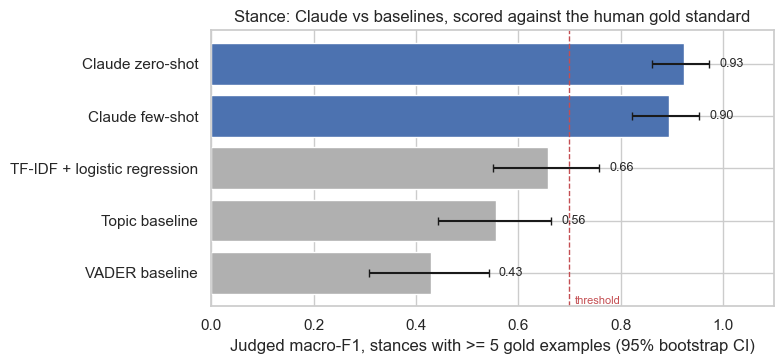

In [144]:
# STANCE SCORES: CLAUDE AND THREE BASELINES
# Every model's stance labels for the 80 gold comments are compared with
# the human gold standard. This is where we find out whether Claude
# beats cheaper methods, and which Claude version to use for all comments.

stance_scores, stance_per_class, stance_merged = None, None, {}

# 1. Wait for the gold standard (the coders' agreed labels)
if gold is None:
    print("PENDING: needs the gold standard (coding/reconcile_gold.xlsx).")
else:
    # 2. Decide which stance categories can be judged fairly.
    # A category with only 1 or 2 gold examples makes F1 swing on a single
    # comment, so the main score averages over categories with at least 5
    # examples; the average over all categories present is reported too.
    counts = gold["stance"].value_counts()
    GOLD_STANCES = [s for s in STANCE_LABELS if s in counts.index]                                     # present in gold
    JUDGED_STANCES = [s for s in GOLD_STANCES if counts[s] >= THRESHOLDS["min_class_support"]]          # enough examples to judge
    assert JUDGED_STANCES, "No stance has enough gold examples to judge"
    print("Stance categories in the gold set:", counts.to_dict())
    print("Judged (>= 5 gold examples):", JUDGED_STANCES)

    # 3. Collect every model's predictions for the gold comments.
    # VADER: tone is turned into a stance the way a naive analyst might
    #   (negative = wants stronger action, positive = supports, neutral = unclear).
    # Topic baseline: ban-related topics = stronger action, all others = unclear.
    # TF-IDF + logistic regression: trained on the gold labels with
    #   cross-validation, so no comment is predicted by a model that saw it.
    g = gold.merge(df[["comment_id", "vader_label", "topic_stance"]], on="comment_id")
    stance_preds = {
        "VADER baseline": g["vader_label"].astype(str).map({"negative": "stronger_action", "positive": "support_as_proposed",
                                                            "neutral": "unclear"}).values,
        "Topic baseline": g["topic_stance"].values,
        "TF-IDF + logistic regression": tfidf_logreg_cv(g["text"], g["stance"]),
    }
    # Claude's labels, put in the same comment order as the gold standard
    for name, res in llm.items():
        stance_preds[name] = g[["comment_id"]].merge(res, on="comment_id")["stance"].values

    # 4. Score each model against the gold standard
    y = g["stance"].values                     # the correct (agreed human) stances
    rows, per_class = [], []
    for name, p in stance_preds.items():
        assert len(p) == len(y), f"{name}: prediction count does not match the gold set"

        # Overall scores:
        #   accuracy             = share of comments with the right stance
        #   macro_f1 (+ 95% CI)  = average F1 over the judged categories (main score)
        #   macro_f1_all_present = average F1 over every category in the gold set
        #   kappa_vs_gold        = agreement beyond chance, comparable with the human kappa
        lo, hi = boot_ci(len(y), lambda i: macro_f1(y[i], p[i], labels=JUDGED_STANCES))
        rows.append({"model": name, "accuracy": accuracy_score(y, p),
                     "macro_f1": macro_f1(y, p, labels=JUDGED_STANCES), "f1_ci_low": lo, "f1_ci_high": hi,
                     "macro_f1_all_present": macro_f1(y, p, labels=GOLD_STANCES), "kappa_vs_gold": kappa(y, p)})

        # Scores per stance category:
        #   precision = when the model says this stance, how often is it right?
        #   recall    = of the comments truly in this stance, how many does it find?
        P, R, F, S = precision_recall_fscore_support(y, p, labels=GOLD_STANCES, zero_division=0)
        per_class += [{"model": name, "stance": c, "precision": pp, "recall": rr, "f1": ff, "gold_examples": int(ss)}
                      for c, pp, rr, ff, ss in zip(GOLD_STANCES, P, R, F, S)]

        # Keep gold vs predicted side by side for the confusion matrix and error analysis
        stance_merged[name] = pd.DataFrame({"comment_id": g["comment_id"], "gold": y, "pred": p})

    stance_scores = pd.DataFrame(rows).round(3).sort_values("macro_f1", ascending=False)
    stance_per_class = pd.DataFrame(per_class).round(3)
    display(stance_scores)

    # 5. Choose the Claude version for the full run.
    # Few-shot sends about twice as many tokens (it includes 20 examples),
    # so it is chosen only if it scores strictly higher than zero-shot.
    f1 = stance_scores.set_index("model")["macro_f1"]
    few_better = "Claude few-shot" in f1 and f1["Claude few-shot"] > f1["Claude zero-shot"]
    BEST = "Claude few-shot" if few_better else "Claude zero-shot"
    BEST_VARIANT = "fewshot" if few_better else "zeroshot"
    BEST_EXAMPLES = pilot_agreed if few_better else None
    print(f"Best Claude version: {BEST}")

    # 6. Chart: each model's main score with its 95% confidence interval.
    # Claude in blue, baselines in grey; the red dashed line is the
    # governance threshold a model must pass for automatic reporting.
    s = stance_scores.sort_values("macro_f1")
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.barh(s["model"], s["macro_f1"], color=["#4C72B0" if m.startswith("Claude") else "#B0B0B0" for m in s["model"]],
            xerr=[(s["macro_f1"] - s["f1_ci_low"]).clip(lower=0), (s["f1_ci_high"] - s["macro_f1"]).clip(lower=0)],
            capsize=3)   # clip: a bootstrap interval can sit slightly off its own point estimate
    ax.axvline(THRESHOLDS["min_stance_macro_f1"], color="#C44E52", ls="--", lw=1)
    ax.text(THRESHOLDS["min_stance_macro_f1"] + 0.01, -0.6, "threshold", color="#C44E52", fontsize=8)
    for i, (v, hi) in enumerate(zip(s["macro_f1"], s["f1_ci_high"])):
        ax.text(hi + 0.02, i, f"{v:.2f}", va="center", fontsize=9)       # score label next to each bar
    ax.set(title="Stance: Claude vs baselines, scored against the human gold standard",
           xlabel="Judged macro-F1, stances with >= 5 gold examples (95% bootstrap CI)", xlim=(0, 1.1))
    plt.tight_layout()
    plt.savefig(FIG / "stance_model_comparison.png", dpi=150, bbox_inches="tight")
    plt.show()

,model,stance,precision,recall,f1,gold_examples
15,Claude zero-shot,stronger_action,0.927,0.950,0.938,40
16,Claude zero-shot,support_as_proposed,1.000,1.000,1.000,2
17,Claude zero-shot,limit_or_oppose_intervention,0.200,1.000,0.333,1
18,Claude zero-shot,mixed_or_conditional,0.000,0.000,0.000,1
19,Claude zero-shot,unclear,0.969,0.861,0.912,36


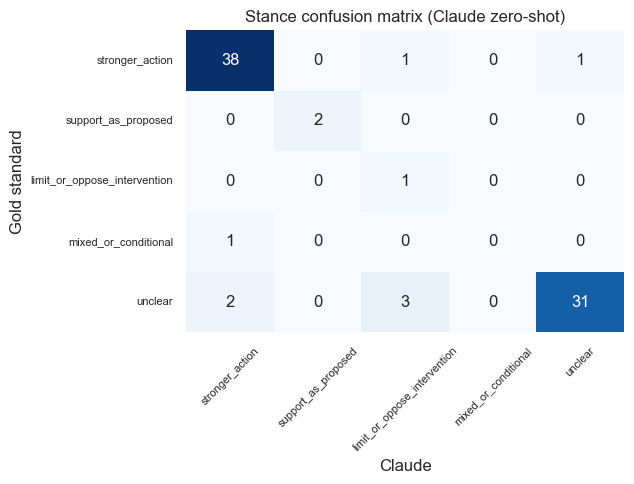

McNemar test, zero-shot vs few-shot stance accuracy: p = 1.000


In [145]:
# STANCE: PER-CATEGORY RESULTS, CONFUSION MATRIX, ZERO-SHOT VS FEW-SHOT
# A closer look at the Claude version chosen above: how it does on each
# stance, which stances it confuses, and whether the two prompt versions
# truly differ or only differ by chance.

# 1. Wait for the gold standard
if gold is None:
    print("PENDING: needs the gold standard.")
else:
    # 2. Precision, recall and F1 for each stance, for the chosen Claude version.
    # gold_examples shows how many comments each score rests on: a score
    # based on 1 or 2 comments should not be over-interpreted.
    display(stance_per_class[stance_per_class["model"] == BEST])

    # 3. Confusion matrix: rows = the correct (gold) stance, columns = Claude's stance.
    # Numbers on the diagonal are correct answers; numbers off the diagonal
    # show which stances Claude mixes up (e.g. 'stronger_action' read as 'unclear').
    # An INVALID column is added only if Claude ever gave an unusable answer.
    m = stance_merged[BEST]
    shown = STANCE_LABELS + (["INVALID"] if (m["pred"] == "INVALID").any() else [])
    cm = confusion_matrix(m["gold"], m["pred"], labels=shown)

    fig, ax = plt.subplots(figsize=(6.5, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=shown, yticklabels=shown, ax=ax)
    ax.set(title=f"Stance confusion matrix ({BEST})", xlabel="Claude", ylabel="Gold standard")
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.tick_params(axis="y", rotation=0, labelsize=8)
    plt.tight_layout()
    plt.savefig(FIG / "stance_confusion_matrix.png", dpi=150, bbox_inches="tight")
    plt.show()

    # 4. Is few-shot really different from zero-shot? (McNemar test)
    # Both versions labeled the same 80 comments, so we compare them
    # comment by comment. Only comments where exactly one version is right
    # matter: if those split roughly evenly, the difference is likely chance.
    # p < 0.05 means the difference in accuracy is unlikely to be chance.
    # Runs only once both versions exist (few-shot needs the pilot examples).
    if {"Claude zero-shot", "Claude few-shot"} <= set(stance_merged):
        from statsmodels.stats.contingency_tables import mcnemar

        # True/False per comment: did each version get the stance right?
        z_ok = stance_merged["Claude zero-shot"]["pred"].values == stance_merged["Claude zero-shot"]["gold"].values
        f_ok = stance_merged["Claude few-shot"]["pred"].values == stance_merged["Claude few-shot"]["gold"].values

        # 2x2 table: both right | only zero-shot right
        #            only few-shot right | both wrong
        table = [[(z_ok & f_ok).sum(), (z_ok & ~f_ok).sum()], [(~z_ok & f_ok).sum(), (~z_ok & ~f_ok).sum()]]

        # Exact version of the test, suitable for small samples like 80 comments
        print(f"McNemar test, zero-shot vs few-shot stance accuracy: p = {mcnemar(table, exact=True).pvalue:.3f}")

### 8.5 Reasons: Claude vs the gold standard

Reasons are multi-label, so each reason is scored as a yes/no prediction:

- **Per-reason precision, recall and F1**, with the number of gold examples.
- **Micro-F1:** pools every reason decision, so common reasons weigh more; it summarizes overall extraction quality.
- **Macro-F1:** the average F1 over reasons with at least 5 gold examples, so rare reasons are not hidden.
- **Exact set match** (all reasons right) and **mean Jaccard** (partial credit for overlapping sets).

The topic baseline predicts at most one reason per comment and is scored the same way.

,model,micro_f1,micro_f1_ci_low,micro_f1_ci_high,macro_f1_judged_reasons,exact_set_match,mean_jaccard
0,Topic baseline,0.387,0.309,0.462,0.276,0.188,0.329
1,Claude zero-shot,0.780,0.721,0.833,0.766,0.462,0.647
2,Claude few-shot,0.836,0.787,0.877,0.783,0.562,0.751


,model,reason,precision,recall,f1,gold_examples
7,Claude zero-shot,privacy_data_use,0.771,0.844,0.806,32
8,Claude zero-shot,transparency_disclosure,1.000,0.500,0.667,10
9,Claude zero-shot,fairness_discrimination_consumer_harm,0.788,0.839,0.812,31
10,Claude zero-shot,pricing_affordability_equal_treatment,0.886,0.756,0.816,41
11,Claude zero-shot,competition_business_economics,1.000,0.571,0.727,7
12,Claude zero-shot,legal_authority_policy_scope,1.000,0.750,0.857,4
13,Claude zero-shot,other,0.000,0.000,0.000,2


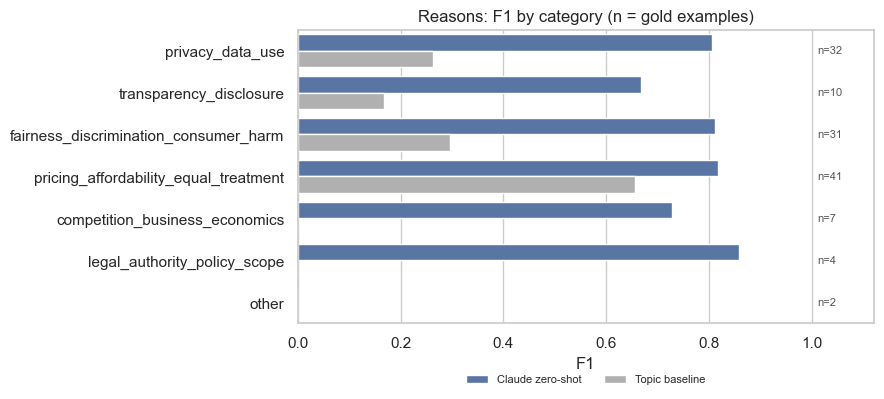

In [146]:
# REASON SCORES
# Scores how well each model finds the REASONS commenters give.
# A comment can have several reasons, so each of the 7 reasons is scored
# as its own yes/no decision, then summarized across all reasons.

reason_scores, reason_per_class = None, None

# 1. Wait for the gold standard
if gold is None:
    print("PENDING: needs the gold standard.")
else:
    # 2. The correct answers as a 0/1 table (rows = comments, columns = reasons)
    Yg = reasons_matrix(gold["reasons"])

    # How many gold comments contain each reason. Reasons with fewer than 5
    # examples are still shown, but left out of the averaged score, because
    # their F1 would swing on one or two comments.
    gold_support = Yg.sum(0)
    judged = gold_support >= THRESHOLDS["min_class_support"]

    # 3. Each model's predicted reason sets for the gold comments.
    # Topic baseline: the one reason linked to the comment's main topic, or
    # no reason for the ban-related topics (they say what people want, not why).
    topic_sets = gold[["comment_id"]].merge(df[["comment_id", "topic_reason"]], on="comment_id")["topic_reason"]
    reason_preds = {"Topic baseline": [frozenset([r]) if isinstance(r, str) else frozenset() for r in topic_sets]}
    # Claude's reason sets, in the same comment order as the gold standard
    for name, res in llm.items():
        reason_preds[name] = gold[["comment_id"]].merge(res, on="comment_id")["reasons"].map(frozenset).tolist()

    # 4. Score each model
    rows, per_class = [], []
    for name, sets in reason_preds.items():
        Yp = reasons_matrix(sets)                 # predictions as a 0/1 table

        # 95% CI for micro-F1, by resampling comments (bootstrap)
        lo, hi = boot_ci(len(Yg), lambda i: f1_score(Yg[i], Yp[i], average="micro", zero_division=0))

        # Precision, recall and F1 for each reason separately
        P, R, F, S = precision_recall_fscore_support(Yg, Yp, average=None, zero_division=0)

        # Overall scores:
        #   micro_f1                = pools every yes/no reason decision; common reasons
        #                             weigh more (the main summary, used for governance)
        #   macro_f1_judged_reasons = plain average of F1 over reasons with >= 5 examples,
        #                             so rarer reasons are not hidden by common ones
        #   exact_set_match         = share of comments where ALL reasons are exactly right
        #   mean_jaccard            = average overlap of predicted vs correct reason sets
        #                             (partial credit: getting 1 of 2 reasons = 0.5)
        rows.append({"model": name, "micro_f1": f1_score(Yg, Yp, average="micro", zero_division=0),
                     "micro_f1_ci_low": lo, "micro_f1_ci_high": hi,
                     "macro_f1_judged_reasons": F[judged].mean() if judged.any() else np.nan,
                     "exact_set_match": (Yg == Yp).all(1).mean(),
                     "mean_jaccard": np.mean([jaccard(x, y) for x, y in zip(gold["reasons"], sets)])})

        # One row per reason, with the number of gold examples it rests on
        per_class += [{"model": name, "reason": r, "precision": pp, "recall": rr, "f1": ff, "gold_examples": int(ss)}
                      for r, pp, rr, ff, ss in zip(REASON_LABELS, P, R, F, S)]

    reason_scores = pd.DataFrame(rows).round(3)
    reason_per_class = pd.DataFrame(per_class).round(3)
    display(reason_scores)                                          # overall comparison of models
    display(reason_per_class[reason_per_class["model"] == BEST])    # per-reason detail for chosen Claude

    # 5. Chart: F1 for each reason, chosen Claude version (blue) vs topic baseline (grey).
    # The n= labels on the right show how many gold examples each score rests on.
    plot = reason_per_class[reason_per_class["model"].isin([BEST, "Topic baseline"])]
    fig, ax = plt.subplots(figsize=(9, 4.2))
    sns.barplot(data=plot, y="reason", x="f1", hue="model", hue_order=[BEST, "Topic baseline"],
                palette=["#4C72B0", "#B0B0B0"], ax=ax)
    for i, r in enumerate(REASON_LABELS):
        ax.text(1.01, i, f"n={gold_support[i]}", va="center", fontsize=8, color="#555555")
    ax.set(title="Reasons: F1 by category (n = gold examples)", xlabel="F1", ylabel="", xlim=(0, 1.12))
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=8, frameon=False)
    plt.tight_layout()
    plt.savefig(FIG / "reasons_f1.png", dpi=150, bbox_inches="tight")
    plt.show()

### 8.6 Run-to-run stability

An LLM can give different answers to the same input, and the current Anthropic API no longer lets us lower the temperature to reduce this. We therefore re-run the best Claude version twice more on 30 gold comments and measure how often all three runs give the identical stance. Unstable labels would make results irreproducible.

In [147]:
# STABILITY TEST: 3 RUNS ON THE SAME 30 COMMENTS
# Does Claude give the same stance when asked the same question again?
# The current API no longer lets us lower the temperature to reduce
# randomness, so consistency must be measured rather than assumed.

stability = None

# 1. Wait until evaluation has chosen the best Claude version (8.4)
if gold is None:
    print("PENDING: needs the best Claude version from 8.4.")
else:
    # 2. Take the first 30 gold comments (STABILITY_N) as the test set.
    # 30 keeps the cost tiny while still showing how often answers change.
    subset = gold_comments[gold_comments["comment_id"].isin(gold_ids[:STABILITY_N])]

    # 3. Run 1 = the answers Claude already gave in 8.3 (no new API calls)
    runs = [llm[BEST].set_index("comment_id").loc[subset["comment_id"], "stance"].values]

    # 4. Runs 2 and 3: send the same comments again, with the same prompt.
    # Each rerun is saved in its own cache file (e.g. zeroshot_rerun2),
    # so it never overwrites the original answers and costs nothing to rerun.
    for k in (2, 3):
        rerun = classify(subset, variant=f"{BEST_VARIANT}_rerun{k}", examples=BEST_EXAMPLES)
        runs.append(rerun.set_index("comment_id").loc[subset["comment_id"], "stance"].values)

    # 5. Stability = share of comments where ALL THREE runs gave the identical stance.
    # (runs is a 3 x 30 grid: one row per run, one column per comment)
    runs = np.array(runs)
    stability = (runs == runs[0]).all(0).mean()
    print(f"Identical stance across 3 runs: {stability:.1%} of {STABILITY_N} comments "
          f"(threshold {THRESHOLDS['min_stability']:.0%})")

    # 6. Agreement between each pair of runs, to see whether one run was unusual
    for i, j in ((0, 1), (0, 2), (1, 2)):
        print(f"  run {i + 1} vs run {j + 1}: {(runs[i] == runs[j]).mean():.1%} agreement")

[zeroshot_rerun2] 30 cached, 0 to classify
[zeroshot_rerun3] 30 cached, 0 to classify
Identical stance across 3 runs: 90.0% of 30 comments (threshold 90%)
  run 1 vs run 2: 93.3% agreement
  run 1 vs run 3: 93.3% agreement
  run 2 vs run 3: 93.3% agreement


### 8.7 Performance by comment length

A classifier can work well on average and badly for one type of comment. We compare stance error rates for short, medium and long comments. A group whose error rate exceeds 1.25 times the best group's triggers investigation (groups with fewer than 10 comments are reported but not judged).

In [148]:
# STANCE ERROR RATE BY COMMENT LENGTH
# Is Claude equally accurate on short, medium and long comments?
# A good average can hide one type of comment where the model does badly,
# so error rates are compared across length groups.

length_slices = None

# 1. Wait for the gold standard
if gold is None:
    print("PENDING: needs the gold standard.")
else:
    # 2. Attach each gold comment's word count to Claude's stance results
    m = stance_merged[BEST].merge(df[["comment_id", "n_words"]], on="comment_id")

    # 3. Sort comments into three length groups
    m["length"] = pd.cut(m["n_words"], [0, 15, 50, 10_000], labels=["short (<=15 words)", "medium (16-50)", "long (>50)"])

    # 4. Mark each comment where Claude's stance differs from the gold standard
    m["error"] = m["gold"] != m["pred"]

    # 5. Number of comments and error rate in each group
    length_slices = m.groupby("length", observed=True).agg(comments=("comment_id", "size"), error_rate=("error", "mean"))

    # 6. Compare every group with the best-performing group.
    # Only groups with at least 10 comments are judged: with fewer, one error
    # changes the rate too much. If the best group made no errors at all, its
    # rate is floored at 1 error in the sample, so the ratio is not a division by zero.
    judged_groups = length_slices[length_slices["comments"] >= 10]
    best_rate = max(judged_groups["error_rate"].min(), 1 / len(m))
    length_slices["ratio_vs_best"] = length_slices["error_rate"] / best_rate

    # 7. Flag a group if its error rate is more than 1.25x the best group's
    # (governance threshold): a signal to investigate, not an automatic failure
    length_slices["flag"] = (length_slices["comments"] >= 10) & (length_slices["ratio_vs_best"] > THRESHOLDS["max_length_error_ratio"])
    display(length_slices.round(3))

,comments,error_rate,ratio_vs_best,flag
length,,,,
short (<=15 words),28,0.036,1.000,False
medium (16-50),28,0.071,2.000,True
long (>50),24,0.208,5.833,True


### 8.8 Where does Claude fail?

Accuracy numbers say how often the model is wrong, not why. We list every gold comment where the best Claude version's stance differs from the gold standard, with Claude's supporting quote, and check whether Claude's own confidence predicts its errors. If low-confidence answers are wrong more often, confidence is a useful signal for routing comments to human review.

In [149]:
# ERROR ANALYSIS
# Accuracy scores say how often Claude is wrong, not why. This cell looks
# at the mistakes themselves, for the chosen Claude version on the 80 gold
# comments, to explain where the model struggles and whether its own
# confidence can be used to catch errors.

# 1. Wait for the gold standard
if gold is None:
    print("PENDING: needs the gold standard.")
else:
    # 2. Put the correct labels (_gold) and Claude's answers (_claude) side by side
    e = gold.merge(llm[BEST][["comment_id", "stance", "reasons", "confidence", "evidence_quote", "quote_found"]],
                   on="comment_id", suffixes=("_gold", "_claude"))

    # Did Claude get the stance wrong?
    e["stance_error"] = e["stance_gold"] != e["stance_claude"]

    # How well do Claude's reasons overlap with the correct ones? (1 = identical sets)
    e["reasons_claude"] = e["reasons_claude"].map(frozenset)
    e["reason_jaccard"] = [jaccard(x, y) for x, y in zip(e["reasons_gold"], e["reasons_claude"])]

    # 3. Does Claude's confidence predict its errors?
    # If 'low' confidence answers are wrong more often than 'high' ones,
    # confidence is a sound rule for routing comments to human review.
    by_conf = e.groupby("confidence").agg(comments=("comment_id", "size"), stance_error_rate=("stance_error", "mean"))
    display(by_conf.round(3))

    # 4. Which mistakes happen most often?
    # Each row is a pair: the correct stance -> the stance Claude chose.
    # A frequent pair points to a boundary in the dictionary that is hard to apply.
    pairs = e[e["stance_error"]].groupby(["stance_gold", "stance_claude"]).size().sort_values(ascending=False)
    print("Most common stance errors (gold -> Claude):")
    display(pairs.to_frame("comments"))

    # 5. List every comment Claude got wrong, for reading.
    # Text is name-masked (privacy) and shortened to 200 characters.
    # The evidence quote shows what Claude based its answer on.
    wrong = e[e["stance_error"]].copy()
    wrong["text"] = wrong["text"].map(mask_names).str[:200]
    cols = ["comment_id", "text", "stance_gold", "stance_claude", "confidence", "evidence_quote"]

    # Saved in full to a file, with the first 10 shown below
    wrong[cols].to_csv(CODING / "claude_stance_errors.csv", index=False)
    print(f"{len(wrong)} of {N_GOLD} gold comments have a stance error -> coding/claude_stance_errors.csv")
    display(wrong[cols].head(10))

,comments,stance_error_rate
confidence,,
high,32,0.031
low,12,0.250
medium,36,0.111


Most common stance errors (gold -> Claude):


comments
stance_gold          stance_claude                         
unclear              limit_or_oppose_intervention         3
                     stronger_action                      2
mixed_or_conditional stronger_action                      1
stronger_action      unclear                              1
                     limit_or_oppose_intervention         1

8 of 80 gold comments have a stance error -> coding/claude_stance_errors.csv


,comment_id,text,stance_gold,stance_claude,confidence,evidence_quote
5,FTC-2026-1057-0891,I am shocked that you are considering allowing companies to charge what they think you can afford. This is discrimin...,unclear,stronger_action,medium,allowing companies to charge what they think you can afford. This is discrimination by retailers.
23,FTC-2026-1057-1729,"It is so devious to have different prices for different people, regardless of criteria. To allow this to continue, w...",unclear,stronger_action,low,"To allow this to continue, will undermine the whole basis of commerce."
24,FTC-2026-1057-0340,"This is a purely totalitarian move by a giant corporation that has partially fused with part of the government, exac...",unclear,limit_or_oppose_intervention,low,"If you approve this, you demonstrate that you are utterly beholden to the corrupt anti-Americans who appointed you"
28,FTC-2026-1057-0882,"So called ""personal pricing"" is a bias system made by to boost corporate profits and nothing more. Price gouging for...",mixed_or_conditional,stronger_action,high,"The price of an item should be based on ITS worth and value, NEVER the person buying it."
32,FTC-2026-1057-1553,"One should not have to pay more than anyone else groceries, home goods, or gasoline.",stronger_action,unclear,medium,"One should not have to pay more than anyone else groceries, home goods, or gasoline."
50,FTC-2026-1057-0474,I have only heard bad things about this surveillance pricing. Businesses have made record profits already with the c...,stronger_action,limit_or_oppose_intervention,medium,"Do not let this rule go into effect, it will not be good or helpful for American consumers like me"
70,FTC-2026-1057-0038,I oppose the FTC’s personal pricing rule. Why should some folks pay more for a product or service just because resea...,unclear,limit_or_oppose_intervention,low,Why should some folks pay more for a product or service just because research has been done on the consumer's backgr...
75,FTC-2026-1057-0218,Does the rule mean that the president wants Americans to pay more for food? Sounds like a great campaign issue for 3...,unclear,limit_or_oppose_intervention,medium,Go ahead and approve ripping Americans off more than they already are currently doing.


## 9. Findings

Claude labels all 1,566 comments. **A label type is reported as a finding only if it passes the governance thresholds** (Section 10); otherwise its numbers are shown but marked as not validated. **Until the hand-coded gold standard exists, the zero-shot version is run and every result is marked PROVISIONAL**: useful for drafting the report and app, but not yet evidence. After evaluation, the best version replaces it. Shares use Wilson 95% confidence intervals. Each share is also recomputed with one comment per near-duplicate group as a sensitivity check. These are shares of **commenters in this sample**, not of the U.S. public.

In [150]:
# PRODUCTION RUN: BEST CLAUDE VERSION ON ALL COMMENTS
# Claude labels all 1,566 comments. These labels are the basis of every
# finding below, of the governance checks and of the Streamlit app.
from statsmodels.stats.proportion import proportion_confint
from scipy.stats import chi2_contingency

# 1. Which Claude version to use.
# Before the gold standard exists, zero-shot is used and everything is marked
# PROVISIONAL. Once evaluation has run, the best version from 8.4 is used.
PROVISIONAL = gold is None
if PROVISIONAL:
    BEST, BEST_VARIANT, BEST_EXAMPLES = "Claude zero-shot", "zeroshot", None
    print("Gold standard not ready: running zero-shot on all comments; results are PROVISIONAL.")

# 2. Label every comment (answers already saved are reused, so reruns cost nothing)
labels_all = classify(df, variant=BEST_VARIANT, examples=BEST_EXAMPLES)
labels_all["reasons"] = labels_all["reasons"].map(frozenset)

# 3. Attach the form-letter flag (for the sensitivity check) and word counts
labels_all = labels_all.merge(df[["comment_id", "is_group_representative", "n_words"]], on="comment_id")
assert len(labels_all) == len(df) and labels_all["comment_id"].is_unique, "Production run incomplete"

# 4. Save the labels for the report and the Streamlit app.
# The status column (provisional / evaluated) travels with the labels.
out = labels_all.drop(columns=["raw"]).assign(reasons=labels_all["reasons"].map(reasons_to_text),
                                              status="provisional" if PROVISIONAL else "evaluated")
out.to_csv(LLM_DIR / "labels_all_comments.csv", index=False)
print(f"Labeled {len(labels_all):,} comments with {BEST} -> outputs/llm/labels_all_comments.csv")

[zeroshot] 1566 cached, 0 to classify
Labeled 1,566 comments with Claude zero-shot -> outputs/llm/labels_all_comments.csv


In [151]:
# WHICH LABEL TYPES PASSED EVALUATION (used to mark every finding below)
# Each finding carries a status, so a reader always knows how far it can be
# trusted: PROVISIONAL (no gold standard yet), validated (passed the
# thresholds), or NOT VALIDATED (failed; human review required).

STATUS = {"stance": "PROVISIONAL (not yet validated)", "reasons": "PROVISIONAL (not yet validated)"}
if gold is not None:
    # Stance passes if macro-F1 reaches the threshold AND every judged stance
    # (>= 5 gold examples) reaches the minimum recall
    sc = stance_scores.set_index("model").loc[BEST]
    pc = stance_per_class[(stance_per_class["model"] == BEST) &
                          (stance_per_class["gold_examples"] >= THRESHOLDS["min_class_support"])]
    stance_ok = sc["macro_f1"] >= THRESHOLDS["min_stance_macro_f1"] and (pc["recall"] >= THRESHOLDS["min_stance_class_recall"]).all()

    # Reasons pass if micro-F1 reaches the threshold
    reasons_ok = reason_scores.set_index("model").loc[BEST, "micro_f1"] >= THRESHOLDS["min_reason_micro_f1"]

    STATUS = {"stance": "validated" if stance_ok else "NOT VALIDATED (human review required)",
              "reasons": "validated" if reasons_ok else "NOT VALIDATED (human review required)"}
for k, v in STATUS.items():
    print(f"{k}: {v}")

stance: validated
reasons: validated


### Part A: What do commenters want the FTC to do? (the policy)

This is what our stance labels measure, and it is fully validated against the hand-coded gold standard (Section 8). Each comment has exactly one stance:

- **Stronger action:** the FTC's rules don't go far enough; most ask for a ban.
- **Support as proposed:** the FTC's disclosure rules are right as they are.
- **Mixed or conditional:** some uses are acceptable and others should be stopped (for example, discounts yes, markups no).
- **Limit or oppose intervention:** the FTC is going too far or lacks the authority.
- **Unclear:** the comment does not say what should happen.

The chart below shows each share with its 95% confidence interval, and the table checks that form letters do not change the result.

0 comments with an invalid stance are excluded (sent to human review)
Stance status: validated


,comments,share,ci_low,ci_high,share_one_per_form_letter
stance,,,,,
stronger_action,1017,0.649,0.625,0.673,0.647
support_as_proposed,26,0.017,0.011,0.024,0.017
limit_or_oppose_intervention,39,0.025,0.018,0.034,0.026
mixed_or_conditional,10,0.006,0.003,0.012,0.007
unclear,474,0.303,0.280,0.326,0.304


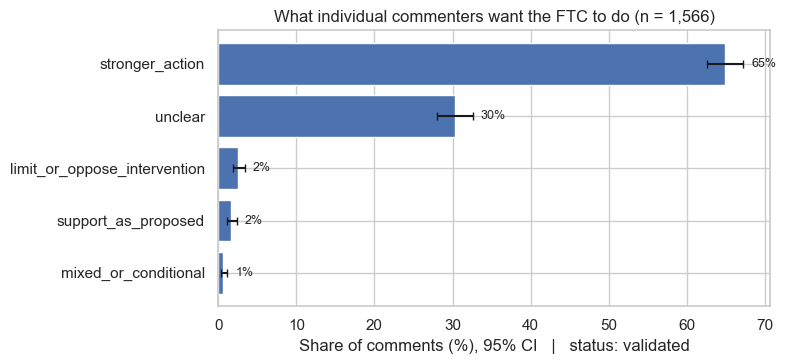

In [152]:
# STANCE: WHAT DO COMMENTERS WANT THE FTC TO DO?
# Share of commenters in each stance, with 95% confidence intervals, plus a
# check that form letters do not drive the result.

# 1. Helpers used by the findings cells
def ci_err(est, lo, hi):
    """Error-bar lengths for charts, clipped at 0 (rounding can push a bound slightly past its estimate)."""
    return [np.clip(np.asarray(est) - np.asarray(lo), 0, None), np.clip(np.asarray(hi) - np.asarray(est), 0, None)]

def share_table(counts, n):
    """Counts -> shares with Wilson 95% confidence intervals (reliable even for small shares)."""
    out = pd.DataFrame({"comments": counts, "share": counts / n})
    out["ci_low"], out["ci_high"] = zip(*[proportion_confint(c, n, method="wilson") for c in counts])
    return out

if labels_all is None:
    print("PENDING: needs the production run.")
else:
    # 2. Comments with an invalid stance are left out of the shares (they go to human review)
    valid = labels_all[labels_all["stance"] != "INVALID"].copy()
    print(f"{len(labels_all) - len(valid)} comments with an invalid stance are excluded (sent to human review)")
    print(f"Stance status: {STATUS['stance']}")

    # 3. Share of each stance, with confidence intervals
    stance_tab = share_table(valid["stance"].value_counts().reindex(STANCE_LABELS, fill_value=0), len(valid))

    # 4. Sensitivity check: the same shares using one comment per near-duplicate group.
    # If removing form letters barely changes the shares, campaigns are not driving the result.
    dedup = valid[valid["is_group_representative"]]
    stance_tab["share_one_per_form_letter"] = dedup["stance"].value_counts(normalize=True).reindex(STANCE_LABELS, fill_value=0)
    display(stance_tab.round(3))
    assert (stance_tab["share"] - stance_tab["share_one_per_form_letter"]).abs().max() < 0.05, \
        "A stance share moves more than 5 points without form letters"

    # 5. Chart: stance shares with 95% confidence intervals
    t = stance_tab.sort_values("share")
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.barh(t.index, t["share"] * 100, xerr=ci_err(t["share"] * 100, t["ci_low"] * 100, t["ci_high"] * 100),
            color="#4C72B0", capsize=3)
    for i, (v, hi) in enumerate(zip(t["share"] * 100, t["ci_high"] * 100)):
        ax.text(hi + 1, i, f"{v:.0f}%", va="center", fontsize=9)           # label just past the error bar
    ax.set(title=f"What individual commenters want the FTC to do (n = {len(valid):,})",
           xlabel=f"Share of comments (%), 95% CI   |   status: {STATUS['stance']}", ylabel="")
    plt.tight_layout()
    plt.savefig(FIG / "finding_stance.png", dpi=150, bbox_inches="tight")
    plt.show()

### Part B: How do commenters feel about personalized pricing itself? (the practice)

Part A is about the FTC's **policy**. Part B asks a different question: are commenters against the **practice** itself (companies charging different people different prices based on their personal data)?

We did not create a separate label for this, so Part B is built in two layers:

1. **A validated minimum, from the stance labels.** Anyone asking for a ban, for stronger rules, or for the FTC's disclosure rules wants the practice controlled, so they are against it as it is used today. That share is a *minimum*: the true share against the practice can only be higher. No stance expresses support for the practice itself; even commenters who oppose the FTC are objecting to the regulation, not defending the pricing.
2. **Supporting evidence for the 30% who did not say what should happen.** For this group we look at what they wrote: whether they give an objection (privacy, fairness, unequal prices or lack of disclosure, from the validated reason labels), and their tone (VADER, from Section 7.1). This shows which way they lean, but it is supporting evidence, not a validated count.

So the honest statement is: *at least this share is against personalized pricing, almost no one defends it, and most of the rest lean against it.* An exact for/against/neutral split would need a new hand-coded label (future work).

Personalized pricing (prices based on your personal data) is also not the same as dynamic pricing (prices that change with demand for everyone).

,comments,share,ci_low,ci_high
practice_view,,,,
Against the practice (validated minimum),1043,0.666,0.642,0.689
Partly against (some uses only),10,0.006,0.003,0.012
Against the FTC's rules (view of the practice not stated),39,0.025,0.018,0.034
Did not say what should happen,474,0.303,0.280,0.326


Comments that did not say what should happen: 474
Give at least one objection reason    0.601
Negative tone (VADER)                 0.498
Positive tone (VADER)                 0.321

At least 67% (95% CI 64%-69%) are against personalized pricing. No stance defends the practice. Of the 30% who did not say what should happen, 60% still give an objection to it.


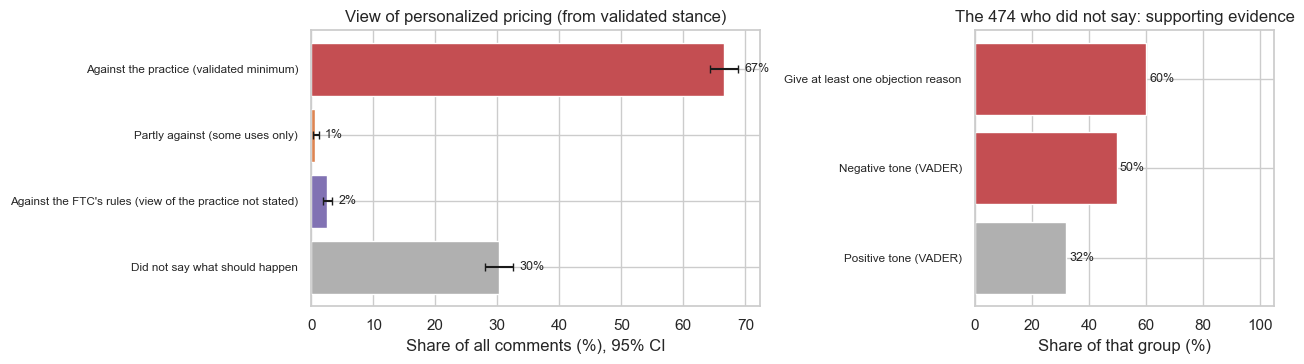

In [153]:
# PART B: HOW DO COMMENTERS FEEL ABOUT PERSONALIZED PRICING ITSELF?
# Turns the validated stance labels into a view of the PRACTICE, then adds
# supporting evidence for the comments whose stance is unclear.
# No new labels are created.

# 1. What each stance tells us about the commenter's view of the practice
PRACTICE_VIEW = {
    "stronger_action": "Against the practice (validated minimum)",
    "support_as_proposed": "Against the practice (validated minimum)",
    "mixed_or_conditional": "Partly against (some uses only)",
    "limit_or_oppose_intervention": "Against the FTC's rules (view of the practice not stated)",
    "unclear": "Did not say what should happen",
}
PRACTICE_ORDER = list(dict.fromkeys(PRACTICE_VIEW.values()))      # the four groups, in this order

# The reasons that are objections to the practice
OBJECTION_REASONS = {"privacy_data_use", "fairness_discrimination_consumer_harm",
                     "pricing_affordability_equal_treatment", "transparency_disclosure"}

if labels_all is None:
    print("PENDING: needs the production run.")
else:
    # 2. Share in each group, with 95% confidence intervals
    valid["practice_view"] = valid["stance"].map(PRACTICE_VIEW)
    assert valid["practice_view"].notna().all(), "Every stance must map to a group"
    practice_tab = share_table(valid["practice_view"].value_counts().reindex(PRACTICE_ORDER, fill_value=0), len(valid))
    display(practice_tab.round(3))

    # 3. Supporting evidence for the group that did not say what should happen:
    # do they give an objection reason (validated labels), and how do they sound (VADER)?
    unsaid = valid[valid["stance"] == "unclear"]
    unsaid_tone = df.set_index("comment_id").loc[unsaid["comment_id"], "vader_label"]
    unsaid_evidence = pd.Series({
        "Give at least one objection reason": unsaid["reasons"].map(lambda r: bool(set(r) & OBJECTION_REASONS)).mean(),
        "Negative tone (VADER)": (unsaid_tone == "negative").mean(),
        "Positive tone (VADER)": (unsaid_tone == "positive").mean(),
    })
    print(f"Comments that did not say what should happen: {len(unsaid):,}")
    print(unsaid_evidence.round(3).to_string())

    # 4. The headline statement for Part B
    a = practice_tab.loc["Against the practice (validated minimum)"]
    print(f"\nAt least {a['share']:.0%} (95% CI {a['ci_low']:.0%}-{a['ci_high']:.0%}) are against personalized pricing. "
          f"No stance defends the practice. Of the {practice_tab.loc['Did not say what should happen', 'share']:.0%} who did not say "
          f"what should happen, {unsaid_evidence.iloc[0]:.0%} still give an objection to it.")

    # 5. Chart, two panels:
    # left = the four groups (validated); right = supporting evidence for the 'did not say' group
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
    t = practice_tab.iloc[::-1]                       # first group drawn at the top
    colors = ["#C44E52", "#DD8452", "#8172B3", "#B0B0B0"][::-1]
    ax1.barh(t.index, t["share"] * 100, xerr=ci_err(t["share"] * 100, t["ci_low"] * 100, t["ci_high"] * 100),
             color=colors, capsize=3)
    for i, (v, hi) in enumerate(zip(t["share"] * 100, t["ci_high"] * 100)):
        ax1.text(hi + 1, i, f"{v:.0f}%", va="center", fontsize=9)
    ax1.set(title="View of personalized pricing (from validated stance)", xlabel="Share of all comments (%), 95% CI", ylabel="")
    ax1.tick_params(axis="y", labelsize=8.5)

    e = unsaid_evidence.iloc[::-1] * 100
    ax2.barh(e.index, e.values, color=["#B0B0B0", "#C44E52", "#C44E52"])   # tone bars are context, so positive is grey, not "for"
    for i, v in enumerate(e.values):
        ax2.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=9)
    ax2.set(title=f"The {len(unsaid):,} who did not say: supporting evidence", xlabel="Share of that group (%)", ylabel="",
            xlim=(0, 105))
    ax2.tick_params(axis="y", labelsize=8.5)
    plt.tight_layout()
    plt.savefig(FIG / "finding_practice_view.png", dpi=150, bbox_inches="tight")
    plt.show()

**How to read these charts.** The left chart groups the five stances by what they imply about the practice. The red bar is the share we can say, with validated labels, is against personalized pricing; it is a minimum. The purple bar is commenters who object to the FTC's rules; they do not say they like the practice. The grey bar is the group that did not say what should happen. The right chart looks inside that grey group: the first bar uses the validated reason labels, the tone bars use VADER and are context only.

Reasons status: validated


,comments,share,ci_low,ci_high,share_one_per_form_letter
privacy_data_use,782,0.499,0.475,0.524,0.497
pricing_affordability_equal_treatment,762,0.487,0.462,0.511,0.489
fairness_discrimination_consumer_harm,747,0.477,0.452,0.502,0.481
transparency_disclosure,155,0.099,0.085,0.115,0.097
competition_business_economics,42,0.027,0.020,0.036,0.027
legal_authority_policy_scope,40,0.026,0.019,0.035,0.026
other,15,0.010,0.006,0.016,0.010


Comments with no stated reason: 15.8% | with 2+ reasons: 53.4%


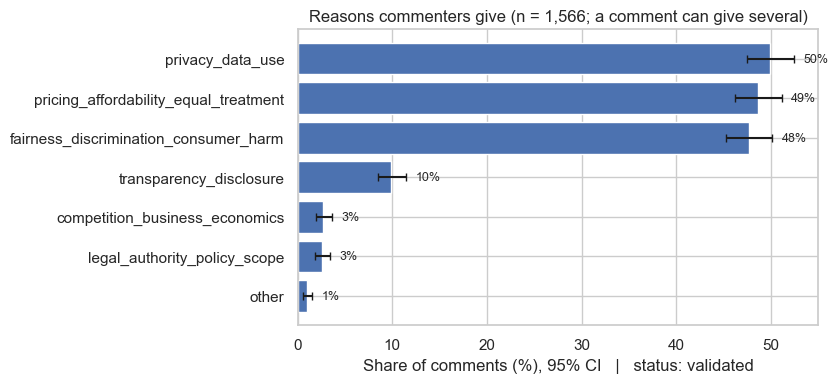

In [154]:
# REASONS: WHY DO COMMENTERS TAKE THEIR POSITION?
# Share of comments giving each reason, with 95% confidence intervals.
# A comment can give several reasons, so the shares add up to more than 100%.

if labels_all is None:
    print("PENDING: needs the production run.")
else:
    print(f"Reasons status: {STATUS['reasons']}")

    # 1. Reasons as a 0/1 table (rows = comments, columns = reasons), then shares with CIs
    Y = reasons_matrix(valid["reasons"])
    reason_tab = share_table(pd.Series(Y.sum(0), index=REASON_LABELS), len(valid))

    # 2. Sensitivity check: the same shares with one comment per near-duplicate group
    reason_tab["share_one_per_form_letter"] = reasons_matrix(dedup["reasons"]).mean(0)
    reason_tab = reason_tab.sort_values("share", ascending=False)
    display(reason_tab.round(3))

    # 3. How many reasons do comments give?
    print(f"Comments with no stated reason: {(Y.sum(1) == 0).mean():.1%} | with 2+ reasons: {(Y.sum(1) >= 2).mean():.1%}")

    # 4. Chart: share of comments giving each reason, with 95% confidence intervals
    t = reason_tab.sort_values("share")
    fig, ax = plt.subplots(figsize=(8.5, 4))
    ax.barh(t.index, t["share"] * 100, xerr=ci_err(t["share"] * 100, t["ci_low"] * 100, t["ci_high"] * 100),
            color="#4C72B0", capsize=3)
    for i, (v, hi) in enumerate(zip(t["share"] * 100, t["ci_high"] * 100)):
        ax.text(hi + 1, i, f"{v:.0f}%", va="center", fontsize=9)
    ax.set(title=f"Reasons commenters give (n = {len(valid):,}; a comment can give several)",
           xlabel=f"Share of comments (%), 95% CI   |   status: {STATUS['reasons']}", ylabel="")
    plt.tight_layout()
    plt.savefig(FIG / "finding_reasons.png", dpi=150, bbox_inches="tight")
    plt.show()

,reason,share_if_stronger_action,share_if_other_stance,chi2,p_value,cramers_v,min_expected_count
0,privacy_data_use,0.622,0.271,175.718,0.000,0.335,274.149
2,fairness_discrimination_consumer_harm,0.578,0.290,118.996,0.000,0.276,261.879
3,pricing_affordability_equal_treatment,0.568,0.335,77.601,0.000,0.223,267.138
1,transparency_disclosure,0.115,0.069,8.396,0.004,0.073,54.339
5,legal_authority_policy_scope,0.033,0.011,7.253,0.007,0.068,14.023
6,other,0.007,0.015,2.222,0.136,0.038,5.259
4,competition_business_economics,0.023,0.035,1.965,0.161,0.035,14.724


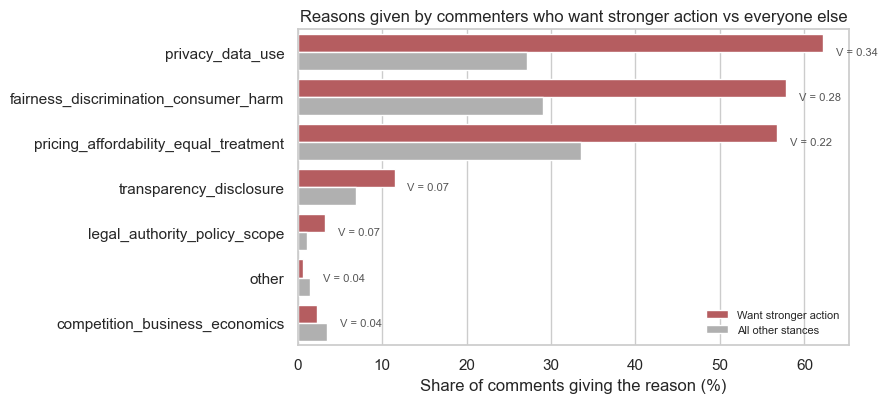

In [155]:
# DO REASONS DIFFER BETWEEN COMMENTERS WHO WANT STRONGER ACTION AND THE REST?
# For each reason, compares how often it appears among commenters who want
# stronger action vs everyone else. A chi-square test checks whether the
# difference could be chance; Cramér's V measures how big it is
# (about 0.1 small, 0.3 medium, 0.5 large).

if labels_all is None:
    print("PENDING: needs the production run.")
else:
    strong = (valid["stance"] == "stronger_action").values      # True for 'stronger action' commenters
    rows = []
    for j, reason in enumerate(REASON_LABELS):
        has = Y[:, j].astype(bool)                               # True if the comment gives this reason

        # 2x2 table: stronger action yes/no  x  reason present yes/no
        table = pd.crosstab(strong, has)
        if table.shape != (2, 2):
            continue                                             # reason never or always present: no test possible
        chi2, p, _, expected = chi2_contingency(table, correction=False)
        rows.append({"reason": reason, "share_if_stronger_action": has[strong].mean(),
                     "share_if_other_stance": has[~strong].mean(), "chi2": chi2, "p_value": p,
                     "cramers_v": np.sqrt(chi2 / table.values.sum()),   # for a 2x2 table this is the phi coefficient
                     "min_expected_count": expected.min()})            # below 5 would make the test unreliable
    assoc = pd.DataFrame(rows).sort_values("cramers_v", ascending=False).round(3)
    assert assoc["cramers_v"].between(0, 1).all()
    display(assoc)

    # Chart: share of each group giving each reason, side by side
    plot = assoc.melt(id_vars="reason", value_vars=["share_if_stronger_action", "share_if_other_stance"],
                      var_name="group", value_name="share")
    plot["group"] = plot["group"].map({"share_if_stronger_action": "Want stronger action",
                                       "share_if_other_stance": "All other stances"})
    plot["share"] *= 100
    fig, ax = plt.subplots(figsize=(9, 4.2))
    sns.barplot(data=plot, y="reason", x="share", hue="group", palette=["#C44E52", "#B0B0B0"], ax=ax)
    for i, r in enumerate(assoc.itertuples()):
        ax.text(max(r.share_if_stronger_action, r.share_if_other_stance) * 100 + 1.5, i,
                f"V = {r.cramers_v:.2f}", va="center", fontsize=8, color="#555555")   # effect size per reason
    ax.set(title="Reasons given by commenters who want stronger action vs everyone else",
           xlabel="Share of comments giving the reason (%)", ylabel="")
    ax.legend(loc="lower right", fontsize=8, frameon=False)
    plt.tight_layout()
    plt.savefig(FIG / "finding_reasons_by_stance.png", dpi=150, bbox_inches="tight")
    plt.show()

## 10. Governance checks

The thresholds fixed at the start of Section 8 are applied here. Each check passes or fails; failures decide what goes to human review and whether results may be reported automatically. The full rules, risk matrix and escalation path are in the governance memo.

,check,value,rule,threshold,passed
0,Human stance kappa,0.954,>=,0.60,True
1,Claude stance macro-F1 (judged stances),0.925,>=,0.70,True
2,Lowest stance recall (categories with >= 5 gold),0.861,>=,0.60,True
3,Claude reason micro-F1,0.780,>=,0.70,True
4,Stance stability across 3 runs,0.900,>=,0.90,True
5,Worst length-group error ratio,5.833,<=,1.25,False
6,Low-confidence share (production),0.120,<=,0.15,True
7,Invalid-answer share (production),0.000,<=,0.02,True
8,Evidence quote found in comment (production),0.953,>=,0.95,True


Checks passed: 8 of 9
Automatic reporting allowed: NO - results are reported only with human review of the queue below


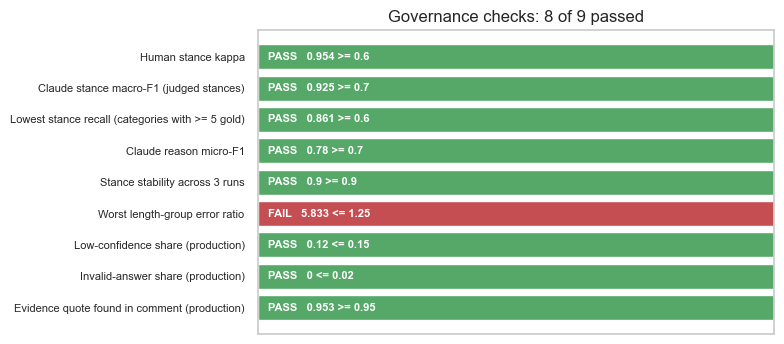

Human-review queue: 256 comments (16.3%) -> coding/human_review_queue.csv
low confidence     188
invalid answer       0
quote not found     73
Random audit: 78 comments (5%) -> coding/audit_sample.csv


In [156]:
# GOVERNANCE CHECKS AND HUMAN-REVIEW QUEUE
# Applies every threshold fixed at the start of Section 8 and records pass or
# fail. If any check fails, results may not be reported automatically: they
# are reported only together with human review of the flagged comments.

if labels_all is None or gold is None:
    print("PENDING: governance checks need the hand-coded gold standard (Section 8).")
else:
    # 1. Gather the evidence for each check
    sc = stance_scores.set_index("model").loc[BEST]                      # stance scores of the chosen Claude version
    rs = reason_scores.set_index("model").loc[BEST]                      # reason scores of the chosen Claude version
    pc = stance_per_class[(stance_per_class["model"] == BEST) & (stance_per_class["gold_examples"] >= THRESHOLDS["min_class_support"])]
    invalid = ((labels_all["stance"] == "INVALID") | labels_all["parse_error"] | labels_all["invalid_reason_label"]).mean()

    # 2. Each check: name, measured value, rule (>= or <=), threshold
    checks = [
        ("Human stance kappa", human_stance["kappa"].iloc[0], ">=", THRESHOLDS["min_human_kappa"]),
        ("Claude stance macro-F1 (judged stances)", sc["macro_f1"], ">=", THRESHOLDS["min_stance_macro_f1"]),
        ("Lowest stance recall (categories with >= 5 gold)", pc["recall"].min(), ">=", THRESHOLDS["min_stance_class_recall"]),
        ("Claude reason micro-F1", rs["micro_f1"], ">=", THRESHOLDS["min_reason_micro_f1"]),
        ("Stance stability across 3 runs", stability, ">=", THRESHOLDS["min_stability"]),
        ("Worst length-group error ratio", length_slices.loc[length_slices["comments"] >= 10, "ratio_vs_best"].max(), "<=",
         THRESHOLDS["max_length_error_ratio"]),
        ("Low-confidence share (production)", (labels_all["confidence"] == "low").mean(), "<=", THRESHOLDS["max_low_confidence_share"]),
        ("Invalid-answer share (production)", invalid, "<=", THRESHOLDS["max_invalid_share"]),
        ("Evidence quote found in comment (production)", labels_all["quote_found"].mean(), ">=", THRESHOLDS["min_quote_found_share"]),
    ]
    governance = pd.DataFrame(checks, columns=["check", "value", "rule", "threshold"])
    governance["passed"] = np.where(governance["rule"] == ">=", governance["value"] >= governance["threshold"],
                                    governance["value"] <= governance["threshold"])
    governance["value"] = governance["value"].astype(float).round(3)
    display(governance)
    print(f"Checks passed: {governance['passed'].sum()} of {len(governance)}")
    print("Automatic reporting allowed:", "YES" if governance["passed"].all() else
          "NO - results are reported only with human review of the queue below")

    # 3. Chart: each check as pass (green) or fail (red), for the slides and memo
    fig, ax = plt.subplots(figsize=(8, 3.6))
    g = governance.iloc[::-1]
    ax.barh(g["check"], [1] * len(g), color=["#55A868" if p else "#C44E52" for p in g["passed"]])
    for i, r in enumerate(g.itertuples()):
        ax.text(0.02, i, f"{'PASS' if r.passed else 'FAIL'}   {r.value:g} {r.rule} {r.threshold:g}",
                va="center", fontsize=8, color="white", fontweight="bold")
    ax.set(xlim=(0, 1), xticks=[], title=f"Governance checks: {governance['passed'].sum()} of {len(governance)} passed")
    ax.tick_params(axis="y", labelsize=8)
    plt.tight_layout()
    plt.savefig(FIG / "governance_checks.png", dpi=150, bbox_inches="tight")
    plt.show()

    # 4. Human-review queue: every comment with low confidence, an invalid answer,
    # or a quote that was not found in the comment (a sign the answer may be made up)
    flags = pd.DataFrame({"low confidence": labels_all["confidence"] == "low",
                          "invalid answer": (labels_all["stance"] == "INVALID") | labels_all["parse_error"] | labels_all["invalid_reason_label"],
                          "quote not found": ~labels_all["quote_found"]})
    review = labels_all[flags.any(axis=1)].copy()
    review["reason_for_review"] = flags[flags.any(axis=1)].apply(lambda r: "; ".join(r.index[r]), axis=1)
    review[["comment_id", "reason_for_review", "stance", "confidence", "evidence_quote"]].to_csv(CODING / "human_review_queue.csv", index=False)

    # 5. Random audit: 5% of all comments, drawn even when every check passes,
    # so a person keeps checking the model over time
    audit = labels_all.sample(frac=THRESHOLDS["audit_share"], random_state=SEED)
    audit[["comment_id", "stance", "evidence_quote"]].assign(reasons=audit["reasons"].map(reasons_to_text)).to_csv(
        CODING / "audit_sample.csv", index=False)
    print(f"Human-review queue: {len(review)} comments ({len(review) / len(labels_all):.1%}) -> coding/human_review_queue.csv")
    print(flags.sum().to_string())
    print(f"Random audit: {len(audit)} comments ({THRESHOLDS['audit_share']:.0%}) -> coding/audit_sample.csv")

## 11. Cost analysis

Costs are measured from the token counts logged with every API call. The comparison with human coding uses the time the coders actually spent (replace the placeholder below with your measured minutes for the 80 gold comments).

Estimated human coding time for the 80 gold comments: 63 minutes per coder (4,526 words at 200 words per minute + 30 seconds per comment)


,calls,mean_input_tokens,mean_output_tokens,cost_per_comment,total_cost,total_minutes,median_seconds
variant,,,,,,,
fewshot,80,5073.43750,130.28750,0.00057,0.04580,1.42917,0.920
smoketest,3,1673.66667,89.00000,0.00021,0.00064,0.04500,0.870
zeroshot,1566,1723.82503,220.79757,0.00028,0.44284,43.27350,1.040
zeroshot_rerun2,30,1749.50000,259.60000,0.00030,0.00914,0.79450,1.535
zeroshot_rerun3,30,1749.50000,275.53333,0.00031,0.00938,0.82217,1.500


Total spent on the API in this project: $0.5078
Claude (zeroshot): $0.00028 and 1.7 seconds per comment | humans: 47 seconds per comment


,comments,llm_cost_usd,llm_hours,human_hours,human_cost_usd,llm_plus_review_usd
0,1000,0.28,0.46,13.05,391.44,19.85
1,10000,2.83,4.61,130.48,3914.38,198.55
2,100000,28.28,46.06,1304.79,39143.75,1985.47


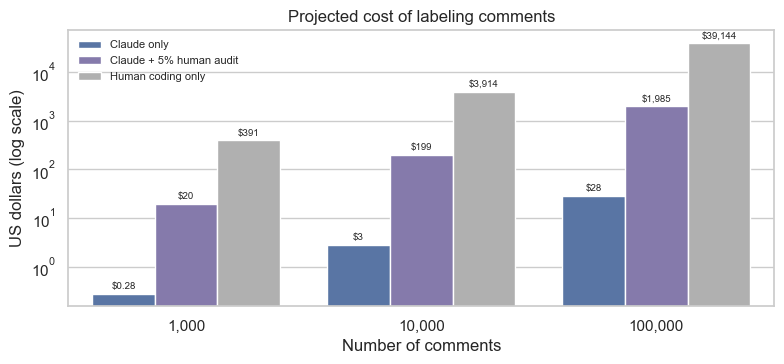

In [157]:
# COST: MEASURED LLM COST AND PROJECTION VS HUMAN CODING
# Every Claude call was logged with its tokens and time (Section 7.5), so cost
# and speed are measured, not estimated. They are compared with the time the
# coders actually spent labeling comments by hand.

# 1. Human-side time and cost (estimated; state these assumptions in the report)
# We did not time ourselves, so human coding time is estimated from the
# length of the 80 gold comments: time to read each comment carefully, plus
# time to choose a stance and tick the reasons. Reconciliation is not included,
# so this is a conservative (low) estimate of the human cost.
READING_WPM = 200                # careful reading speed, words per minute
DECISION_SECONDS = 30            # time to pick a stance and tick reasons for one comment
HUMAN_HOURLY_RATE = 30.0         # USD per hour for an analyst (assumption)

gold_words = df.loc[df["comment_id"].isin(gold_ids), "n_words"]       # word count of each gold comment
HUMAN_MINUTES_FOR_GOLD = (gold_words.sum() / READING_WPM * 60 + DECISION_SECONDS * len(gold_words)) / 60
print(f"Estimated human coding time for the {len(gold_words)} gold comments: {HUMAN_MINUTES_FOR_GOLD:.0f} minutes per coder "
      f"({gold_words.sum():,} words at {READING_WPM} words per minute + {DECISION_SECONDS} seconds per comment)")

# 2. Load every logged Claude call and price it
log_files = list(LLM_DIR.glob("labels_*.jsonl"))
assert log_files, "No LLM calls logged yet: run Section 7.5 first"
logs = pd.concat([pd.read_json(p, lines=True) for p in log_files], ignore_index=True)
assert (logs["input_tokens"] > 0).all() and (logs["output_tokens"] > 0).all(), "Missing token counts"
logs["cost_usd"] = (logs["input_tokens"] * PRICE_IN_PER_MTOK + logs["output_tokens"] * PRICE_OUT_PER_MTOK) / 1e6

# 3. Cost and speed per run (smoke test, zero-shot, few-shot, stability reruns)
per_variant = logs.groupby("variant").agg(calls=("comment_id", "size"), mean_input_tokens=("input_tokens", "mean"),
                                          mean_output_tokens=("output_tokens", "mean"),
                                          cost_per_comment=("cost_usd", "mean"), total_cost=("cost_usd", "sum"),
                                          total_minutes=("latency_s", lambda s: s.sum() / 60),
                                          median_seconds=("latency_s", "median"))
display(per_variant.round(5))
print(f"Total spent on the API in this project: ${logs['cost_usd'].sum():.4f}")

# 4. Per-comment cost and time of the version used in production, vs humans
production_variant = BEST_VARIANT if gold is not None else "zeroshot"
llm_cost_per_comment = logs.loc[logs["variant"] == production_variant, "cost_usd"].mean()
llm_seconds_per_comment = logs.loc[logs["variant"] == production_variant, "latency_s"].mean()
human_seconds_per_comment = HUMAN_MINUTES_FOR_GOLD * 60 / N_GOLD
print(f"Claude ({production_variant}): ${llm_cost_per_comment:.5f} and {llm_seconds_per_comment:.1f} seconds per comment | "
      f"humans: {human_seconds_per_comment:.0f} seconds per comment")

# 5. Projection to larger dockets: cost and time, Claude vs humans.
# 'llm_plus_review' adds a person auditing 5% of comments (governance rule).
# Claude time assumes one comment at a time, as in this notebook; sending
# comments in parallel would be much faster.
projection = pd.DataFrame({"comments": [1_000, 10_000, 100_000]})
projection["llm_cost_usd"] = projection["comments"] * llm_cost_per_comment
projection["llm_hours"] = projection["comments"] * llm_seconds_per_comment / 3600
projection["human_hours"] = projection["comments"] * human_seconds_per_comment / 3600
projection["human_cost_usd"] = projection["human_hours"] * HUMAN_HOURLY_RATE
projection["llm_plus_review_usd"] = projection["llm_cost_usd"] + projection["human_cost_usd"] * THRESHOLDS["audit_share"]
display(projection.round(2))

# 6. Chart: projected cost on a log scale (the gap is too large for a normal scale)
plot = projection.melt(id_vars="comments", value_vars=["llm_cost_usd", "llm_plus_review_usd", "human_cost_usd"],
                       var_name="approach", value_name="usd")
plot["approach"] = plot["approach"].map({"llm_cost_usd": "Claude only", "llm_plus_review_usd": "Claude + 5% human audit",
                                         "human_cost_usd": "Human coding only"})
plot["comments"] = plot["comments"].map(lambda n: f"{n:,}")
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.barplot(data=plot, x="comments", y="usd", hue="approach", palette=["#4C72B0", "#8172B3", "#B0B0B0"], ax=ax)
ax.set_yscale("log")
for cont in ax.containers:
    ax.bar_label(cont, labels=[f"${v:,.0f}" if v >= 1 else f"${v:.2f}" for v in cont.datavalues], fontsize=7, padding=2)
ax.set(title="Projected cost of labeling comments", xlabel="Number of comments", ylabel="US dollars (log scale)")
ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig(FIG / "cost_projection.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Answers to the business questions

This section returns to the questions set out in Section 1 and answers each one from the evidence above. Every answer carries its status: **validated** (passed the governance thresholds), **not validated** (failed them; human review required), **provisional** (the hand-coded gold standard is not finished yet), or **pending**.

- **Questions 1–4** are about the *workflow*: can an organization rely on GenAI to analyze comments, at what cost, where does it fail, and under what controls?
- **Questions 5–6** are about the *findings*: what individual commenters object to and what they want the FTC to do, for companies that use personalized pricing.

In [158]:
# ANSWERS TO THE BUSINESS QUESTIONS (built from the results above)
# Returns to the six questions from Section 1 and answers each one in a
# sentence, using the numbers computed above. Each answer carries its status,
# and any question whose evidence is not ready yet says PENDING.

# Small helpers to format percentages and confidence intervals
def pct(x):
    return f"{x:.0%}"

def ci(lo, hi):
    return f"95% CI {lo:.0%}-{hi:.0%}"

answers = {}

# Q1. How accurately does an LLM classify comments compared with human coders?
# Claude's stance score and agreement with the gold standard, next to the
# human-human agreement and the best cheaper method.
if gold is None:
    answers["1. Accuracy vs human coders"] = "PENDING: needs the hand-coded gold standard (Section 8)."
else:
    sc = stance_scores.set_index("model")
    b, rs = sc.loc[BEST], reason_scores.set_index("model").loc[BEST]
    best_base = sc.drop(index=[m for m in sc.index if m.startswith("Claude")])["macro_f1"].idxmax()
    answers["1. Accuracy vs human coders"] = (
        f"{BEST} labels stance with judged macro-F1 {b['macro_f1']:.2f} (95% CI {b['f1_ci_low']:.2f}-{b['f1_ci_high']:.2f}) and "
        f"{pct(b['accuracy'])} accuracy; its agreement with the gold standard (kappa {b['kappa_vs_gold']:.2f}) compares with "
        f"human-human kappa {human_stance['kappa'].iloc[0]:.2f}. The best cheaper method ({best_base}) reaches "
        f"{sc.loc[best_base, 'macro_f1']:.2f}. Reasons: micro-F1 {rs['micro_f1']:.2f}. Status: stance {STATUS['stance']}, "
        f"reasons {STATUS['reasons']}.")

# Q2. What does it cost per comment compared with human analysts?
# Measured Claude cost and the projection to 100,000 comments (Section 11).
row = projection.set_index("comments").loc[100_000]
answers["2. Cost vs human analysts"] = (
    f"Measured cost: ${llm_cost_per_comment:.5f} per comment ({production_variant}). Labeling 100,000 comments would cost "
    f"about ${row['llm_cost_usd']:,.0f} with Claude, versus {row['human_hours']:,.0f} analyst hours (${row['human_cost_usd']:,.0f}) "
    f"by hand; with a {THRESHOLDS['audit_share']:.0%} human audit, about ${row['llm_plus_review_usd']:,.0f}. "
    f"Human time is estimated at {HUMAN_MINUTES_FOR_GOLD:.0f} minutes per coder for the {N_GOLD} gold comments, from their length (Section 11).")

# Q3. Where does it fail?
# The most common error, any comment-length group flagged, and stability.
if gold is None:
    answers["3. Where it fails"] = "PENDING: needs the gold standard to compare Claude's labels with."
else:
    top = pairs.index[0] if len(pairs) else None
    flagged = length_slices.index[length_slices["flag"]].tolist()
    answers["3. Where it fails"] = (
        (f"Most common stance error: gold '{top[0]}' labeled '{top[1]}' ({pairs.iloc[0]} of {N_GOLD} comments). " if top else "No stance errors. ")
        + (f"Error rate is disproportionately high for {', '.join(map(str, flagged))}. " if flagged else "No length group is flagged. ")
        + f"Stance was identical across 3 runs for {pct(stability)} of comments. Errors are listed in coding/claude_stance_errors.csv.")

# Q4. What controls make it safe to use?
# The governance result: checks passed, whether automatic reporting is allowed,
# and how much goes to human review.
if gold is None:
    answers["4. Controls needed"] = ("PENDING: governance checks need the gold standard. Controls already in place: thresholds fixed "
                                     "before evaluation, schema and quote checks on every answer, name masking, cached and logged calls.")
else:
    failed = governance.loc[~governance["passed"], "check"].tolist()
    answers["4. Controls needed"] = (
        f"{governance['passed'].sum()} of {len(governance)} governance checks passed"
        + (f"; failed: {', '.join(failed)}" if failed else "")
        + f". Automatic reporting is {'allowed' if not failed else 'NOT allowed'}. {len(review)} comments "
          f"({len(review) / len(labels_all):.0%}) go to human review (low confidence, invalid answer, or quote not found), "
          f"plus a {THRESHOLDS['audit_share']:.0%} random audit of every run.")

# Q5. What do commenters object to: the price difference, the use of their data, or the lack of disclosure?
# The three reasons named in the question, with confidence intervals.
r = reason_tab
three = {"the price difference": "pricing_affordability_equal_treatment", "the use of their data": "privacy_data_use",
         "the lack of disclosure": "transparency_disclosure"}
answers["5. What commenters object to"] = (
    "; ".join(f"{name}: {pct(r.loc[lab, 'share'])} ({ci(r.loc[lab, 'ci_low'], r.loc[lab, 'ci_high'])})" for name, lab in three.items())
    + f". Fairness and consumer harm: {pct(r.loc['fairness_discrimination_consumer_harm', 'share'])}. "
      f"A comment can give several reasons. Status: {STATUS['reasons']}.")

# Q6. What do they want the FTC to do?
# Part A: stance shares (the policy). Part B: the validated minimum against the practice.
t = stance_tab
answers["6. What commenters want the FTC to do"] = (
    f"Part A (the policy): stronger action than proposed: {pct(t.loc['stronger_action', 'share'])} "
    f"({ci(t.loc['stronger_action', 'ci_low'], t.loc['stronger_action', 'ci_high'])}); "
    f"support as proposed: {pct(t.loc['support_as_proposed', 'share'])}; mixed or conditional: {pct(t.loc['mixed_or_conditional', 'share'])}; "
    f"limit or oppose: {pct(t.loc['limit_or_oppose_intervention', 'share'])}; unclear: {pct(t.loc['unclear', 'share'])}. "
    f"Part B (the practice): at least {pct(practice_tab.loc['Against the practice (validated minimum)', 'share'])} are against "
    f"personalized pricing, no stance defends it, and {pct(unsaid_evidence.iloc[0])} of those who did not say what should happen "
    f"still give an objection to it. Status: {STATUS['stance']}.")

# Print the answers, and check none is missing
for q, a in answers.items():
    print(f"{q}\n   {a}\n")
assert len(answers) == 6, "Every business question must have an answer or a PENDING note"

1. Accuracy vs human coders
   Claude zero-shot labels stance with judged macro-F1 0.93 (95% CI 0.86-0.97) and 90% accuracy; its agreement with the gold standard (kappa 0.82) compares with human-human kappa 0.95. The best cheaper method (TF-IDF + logistic regression) reaches 0.66. Reasons: micro-F1 0.78. Status: stance validated, reasons validated.

2. Cost vs human analysts
   Measured cost: $0.00028 per comment (zeroshot). Labeling 100,000 comments would cost about $28 with Claude, versus 1,305 analyst hours ($39,144) by hand; with a 5% human audit, about $1,985. Human time is estimated at 63 minutes per coder for the 80 gold comments, from their length (Section 11).

3. Where it fails
   Most common stance error: gold 'unclear' labeled 'limit_or_oppose_intervention' (3 of 80 comments). Error rate is disproportionately high for medium (16-50), long (>50). Stance was identical across 3 runs for 90% of comments. Errors are listed in coding/claude_stance_errors.csv.

4. Controls needed


### What this means

**For organizations adopting GenAI to analyze public comments** (regulators, law firms, public-affairs teams), Questions 1–4:

- **GenAI is a strong first-pass reader, not a replacement for analysts.** In our run Claude zero-shot matched the hand-coded gold standard on stance with macro-F1 0.93 and kappa 0.82 (humans agreed with each other at kappa 0.95), far above sentiment (0.43), topics (0.56) and a trained TF-IDF classifier (0.66). Its value is concentrating human attention: it labels every comment for a fraction of a cent and routes the uncertain ones (about 16%) to people.
- **It fails in predictable places.** Errors rise with comment length (21% on long comments vs 4% on short ones), it sometimes reads anger at personalized pricing as opposition to the FTC (it predicted *limit or oppose* 5 times for 1 real case), and it misses some transparency arguments. Its own confidence rating predicts its errors, which is what makes a review queue work.
- **Validation is the real cost.** Running the model on 1,566 comments cost about $0.44; building the human gold standard and checking the model against it is where the time goes, and it must be repeated when the model, prompt or topic changes.
- **Controls must be measurable.** 8 of 9 governance checks passed; the length check failed, so results are reported only together with human review of the flagged comments.

**For companies that use personalized pricing** (retailers, platforms, travel and ride-sharing firms), Questions 5–6:

- **Disclosure alone is unlikely to defuse public opposition.** About two thirds of individual commenters (65%) want stronger action than the FTC proposed, typically a ban, while under 2% support the proposal as it stands and under 3% want less regulation (and that last figure is probably overstated, see Section 8.4).
- **The objection is to data use and unequal prices, not to secrecy.** Personal-data use (50%), the price difference itself (49%) and fairness (48%) dominate; lack of disclosure is cited by only about 10%. Companies relying on "we disclosed it" as their defense may be misreading where public pressure is heading.
- **These are commenters, not the public.** People who comment are self-selected and more likely to hold strong views, so these shares indicate the direction of regulatory pressure, not public opinion as a whole.



## 13. Reproducibility record

In [159]:
# VERSIONS, SETTINGS AND DATA FINGERPRINT
# Records everything needed to reproduce these results: software versions,
# the random seed, the model and prompt settings, sample sizes, and a
# fingerprint (hash) of the data file, which changes if the data changes.
import hashlib, platform, sklearn, scipy

record = {
    "python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
    "scikit-learn": sklearn.__version__, "scipy": scipy.__version__, "anthropic": anthropic.__version__,
    "seed": SEED, "model": LLM_MODEL, "sampling": SAMPLING, "effort": EFFORT, "prompt_version": PROMPT_VERSION,
    "comments_analyzed": len(df), "pilot": N_PILOT, "gold": N_GOLD, "coders": ", ".join(CODERS),
    "data_file_sha256": hashlib.sha256(DATA_FILE.read_bytes()).hexdigest()[:16],
}
for k, v in record.items():
    print(f"{k}: {v}")

python: 3.12.14
pandas: 3.0.5
numpy: 2.2.6
scikit-learn: 1.4.2
scipy: 1.14.1
anthropic: 2.3.0
seed: 20261027
model: claude-haiku-5-5
sampling: API default
effort: low
prompt_version: v2
comments_analyzed: 1566
pilot: 20
gold: 80
coders: coder1, coder2
data_file_sha256: 8996de271e62c007
